# Bank Marketing - Python Dataset Analysis & Machine Learning

Group assignment for the course: Data Science Programming Languages and tools

(A26_I_DTS_DL_04)

Alice Davolio, Alessandro Lupo, Daniele Calabrese, Ena Karkelja, Ioanna Kyrkoudi, Isabela Rule Muñoz



# Abstract

Nowadays, Python, a high level programming language, is used not only for building software and automation but especially for analyzing data and applying artificial intelligence techniques such as machine learning and deep learning to extract hidden patterns and insight into data, relevant for taking data-driven decision.

In this notebook, an analysis of the Bank marketing dataset is performed following the lifecycle of machine learning project:

1. Exploratory Data Analysis
2. Prepare the data
3. Machine Learning Models
4. Compare different models
5. Feature Engineering & Parameter tuning
6. Interpret the result


# Dataset

The data is related with direct marketing campaigns (phone calls) of a Portuguese banking institution.

The marketing campaigns were based on phone calls. Often, more than one contact to the same client was required, in order to access if the product (bank term deposit) would be ('yes') or not ('no') subscribed.

The classification goal is to predict if the client will subscribe a term deposit (variable y).

There are four datasets:
1) bank-additional-full.csv with all examples (41188) and 20 inputs, ordered by date (from May 2008 to November 2010).
2) bank-additional.csv with 10% of the examples (4119), randomly selected from 1), and 20 inputs.
3) bank-full.csv with all examples and 17 inputs, ordered by date (older version of this dataset with less inputs).
4) bank.csv with 10% of the examples and 17 inputs, randomly selected from 3 (older version of this dataset with less inputs).

In this notebook it is analyzed the 3. bank-full.csv dataset.

Creators of the dataset: S. Moro, P. Rita, P. Cortez

# Python packages

The following libraries and packages were used to analyze the Bank Marketing Dataset, perform data preprocessing, develop Machine Learning models, and evaluate their performance.
1. Data Loading and File Management
- os – for working with files and directories.
- io – for handling input/output data streams.
- zipfile – for extracting files from ZIP archives.
- urllib.request – for downloading the dataset from a URL.
2. Data Manipulation and Analysis
- NumPy – for numerical calculations, array manipulation, and data handling.
- Pandas – for loading, cleaning, transforming, and analyzing the dataset.
3. Data Visualization
- Matplotlib – for creating plots and visualizations, including ROC curves and confusion matrices.
- Seaborn – for statistical visualizations, such as bar charts and correlation heatmaps.
- IPython.display – for displaying DataFrames and results clearly within the notebook.
4. Data Preprocessing — Scikit-learn
- ColumnTransformer – for applying different preprocessing techniques to selected columns.
- OneHotEncoder – for converting categorical features into binary numerical columns.
- StandardScaler – for standardizing numerical features to have a mean of 0 and a standard deviation of 1.
- LabelEncoder – for converting categorical labels into numerical values.
- Pipeline – for combining preprocessing and Machine Learning steps into a single workflow.
5. Machine Learning Models
- LogisticRegression – for building a linear classification model to predict customer subscriptions to a term deposit.
- RandomForestClassifier – for training an ensemble model that combines multiple decision trees to make predictions.
- XGBoost – for training a Gradient Boosting model that sequentially builds decision trees to improve predictions.
6. Dataset Splitting and Hyperparameter Tuning — Scikit-learn
- train_test_split – for dividing the dataset into training and testing subsets.
- StratifiedKFold – for performing cross-validation while maintaining similar class proportions across the folds.
- GridSearchCV – for identifying suitable hyperparameters by testing different combinations through cross-validation.
7. Model Evaluation — Scikit-learn
- accuracy_score – for calculating the proportion of correctly classified observations.
- precision_score – for measuring the proportion of correct positive predictions among all positive predictions.
- recall_score – for measuring the proportion of actual positive observations correctly identified by the model.
- f1_score – for calculating the harmonic mean of Precision and Recall.
- classification_report – for generating a summary of classification metrics, including Precision, Recall, F1-score, and support.
- confusion_matrix – for comparing predicted classes with actual classes and identifying classification errors.
- ConfusionMatrixDisplay – for visualizing the confusion matrix.
- roc_curve – for calculating the True Positive Rate and False Positive Rate across different classification thresholds.
- auc – for calculating the area under a curve.
- roc_auc_score – for evaluating the model's ability to distinguish between positive and negative classes using ROC-AUC.
- RocCurveDisplay – for visualizing the Receiver Operating Characteristic (ROC) Curve.



In [319]:
import os, io, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
import xgboost as xgb
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, accuracy_score


sns.set_theme(style="whitegrid")

# 1 Explore the data (EDA)


Before training predictive machine learning models, it is essential to deeply understand the underlying patterns, structures, and anomalies within our dataset. This initial phase of **Exploratory Data Analysis (EDA)** allows us to assess data quality, evaluate variables individually, and identify key relationships that correlate with our target variable: whether a customer decides to subscribe to a term deposit (`y`).

This analysis follows a structured **6-step roadmap**:

1. **First look at the data**: Inspecting dimensions, data types, missing values, and hidden missing values disguised as "unknown" placeholders.
2. **How many customers subscribed?**: Examining the distribution of our target variable to evaluate class balance and set realistic expectations for baseline model evaluation.
3. **Numerical variables**: Checking distribution shapes, identifying extreme outliers, and measuring variables with skewed distributions.
4. **Numerical variables vs. subscription**: Investigating how numeric characteristics (like age, account balance, and campaign frequency) affect the likelihood of a term deposit subscription.
5. **Categorical variables vs. subscription**: Identifying the categorical features (such as job type, marital status, and previous campaign success) that show the strongest differences in subscription rates.
6. **Correlation and summary**: Summarizing linear relationships with a correlation heatmap and consolidating key insights to shape our feature engineering and preprocessing decisions.


## 1.1 Load the data
The file `bank-full.csv` uses `;` as separator. If the file is not in the folder, the code downloads it from UCI.

In [320]:
def load_bank_full():
    if os.path.exists("bank-full.csv"):
        return pd.read_csv("bank-full.csv", sep=";")
    url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
    raw = urllib.request.urlopen(url).read()
    outer = zipfile.ZipFile(io.BytesIO(raw))
    inner = zipfile.ZipFile(io.BytesIO(outer.read("bank.zip")))
    return pd.read_csv(inner.open("bank-full.csv"), sep=";")

df = load_bank_full()
df["y_num"] = (df["y"] == "yes").astype(int)      # 1 = subscribed, 0 = not subscribed

num_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c]) and c != "y_num"]
cat_cols = [c for c in df.columns if c not in num_cols + ["y", "y_num"]]
overall = df["y_num"].mean() * 100

## 1.2 First look at the data

In [321]:
print("Rows and columns:", df.shape[0], "and", df.shape[1] - 1)
display(df.drop(columns="y_num").head())
print("Missing values (empty cells):", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())

Rows and columns: 45211 and 17


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


Missing values (empty cells): 0
Duplicated rows: 0


In [322]:
# Missing information is hidden in the text "unknown"
unknown = ((df[cat_cols] == "unknown").mean() * 100).round(1)
print("Share of 'unknown' per column (%):")
print(unknown[unknown > 0].to_string())
print()
print("pdays = -1 means 'never contacted before': {:.1f}% of customers".format((df["pdays"] == -1).mean() * 100))

Share of 'unknown' per column (%):
job           0.6
education     4.1
contact      28.8
poutcome     81.7

pdays = -1 means 'never contacted before': 81.7% of customers


**What we see:**
- The data has 45211 rows and 17 columns
- There are no duplicated rows
- The data has no empty cells, but some columns use the text **"unknown"** for missing information. We keep it as its own category.
- `pdays = -1` is not a real number of days: it is a code for *"customer was not contacted in a previous campaign"*.

## 1.3 How many customers subscribed?

No :  39922  (88.3%)
Yes:   5289  (11.7%)


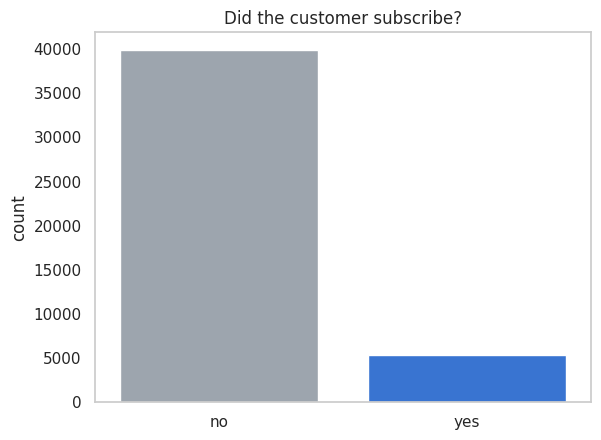

In [323]:
counts = df["y"].value_counts()
print(f"No : {counts['no']:>6}  ({counts['no'] / len(df) * 100:.1f}%)")
print(f"Yes: {counts['yes']:>6}  ({counts['yes'] / len(df) * 100:.1f}%)")

sns.countplot(data=df, x="y", order=["no", "yes"], hue="y", palette=["#9aa5b1", "#1f6feb"], legend=False)
plt.title("Did the customer subscribe?"); plt.xlabel("")
plt.grid(False)
plt.show()

**What we see:** only about 1 in 8 customers subscribed. The data is **imbalanced**, so a model that always predicts "no" would be ~88% correct and still useless. Later we must look at precision and recall, not only accuracy.

## 1.4 Numerical variables
Charts are cut at the 99th percentile so that a few extreme values do not hide the main part of the data.

In [324]:
display(df[num_cols].describe().T.round(1))

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.9,10.6,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.3,3044.8,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.8,8.3,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.2,257.5,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.8,3.1,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.2,100.1,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.6,2.3,0.0,0.0,0.0,0.0,275.0


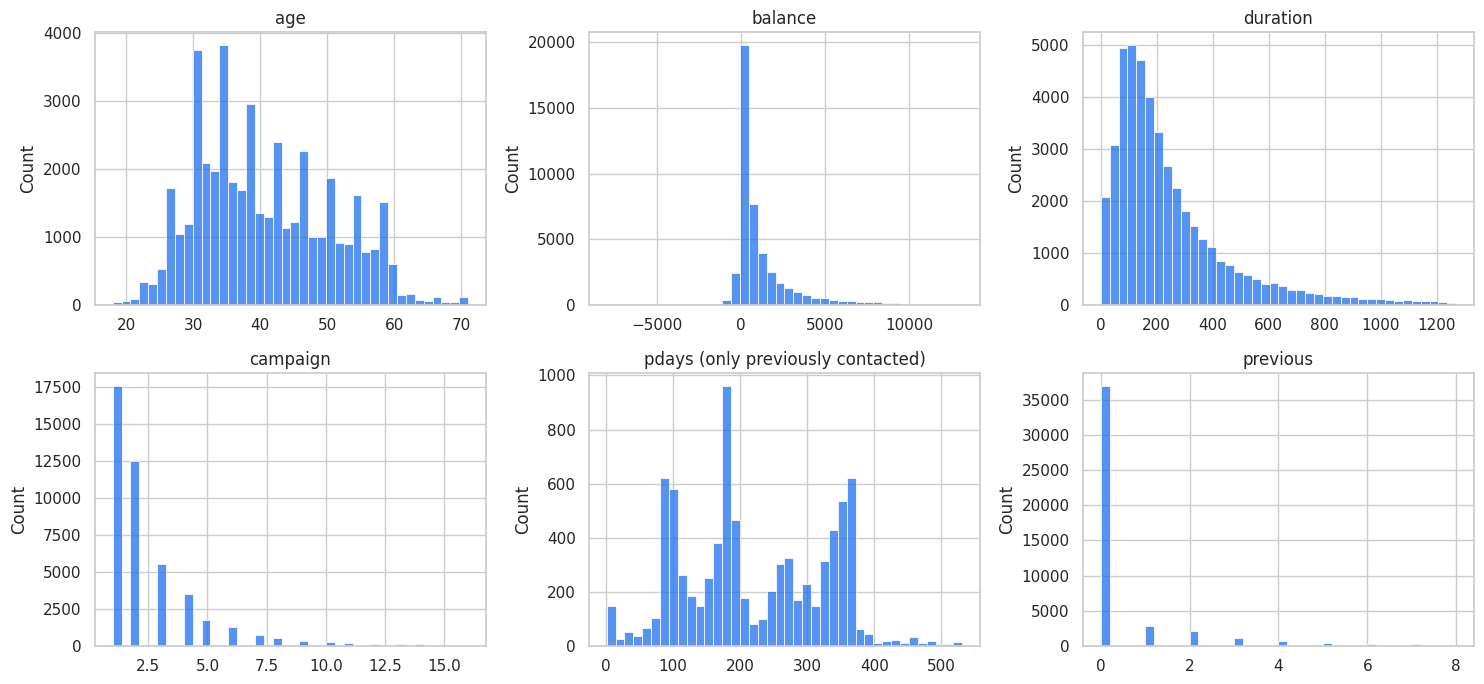

Skewness (above 2 = very long tail to the right):
age          0.7
balance      8.4
day          0.1
duration     3.1
campaign     4.9
pdays        2.6
previous    41.8


In [325]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), ["age", "balance", "duration", "campaign", "pdays", "previous"]):
    data = df[df["pdays"] != -1] if col == "pdays" else df
    cut = data[col].quantile(0.99)
    sns.histplot(data[data[col] <= cut][col], bins=40, ax=ax, color="#1f6feb")
    ax.set_title(col + (" (only previously contacted)" if col == "pdays" else ""))
    ax.set_xlabel("")
plt.tight_layout(); plt.show()

skew = df[num_cols].skew().round(1)
print("Skewness (above 2 = very long tail to the right):")
print(skew.to_string())

**What we see:**
- `age` is spread between about 20 and 60 years.
- `balance`, `campaign`, `previous` and `duration` have a **long tail to the right**: most customers have small values and a few have very large ones (balance up to ~100,000 EUR; some customers were called more than 30 times).
- Because of these extreme values, the **median** describes a typical customer better than the mean.

### 1.4.1 Numerical variables vs. subscription

**Average value of each numerical variable for customers who said "no" and "yes":**

In [326]:
display(df.groupby("y")[num_cols].mean().round(1))

,age,balance,day,duration,campaign,pdays,previous
y,,,,,,,
no,40.8,1303.7,15.9,221.2,2.8,36.4,0.5
yes,41.7,1804.3,15.2,537.3,2.1,68.7,1.2


Now the **subscription rate** (% of customers in each group who said yes). The red dashed line is the overall rate. A bar above the line means the group subscribes more than average.

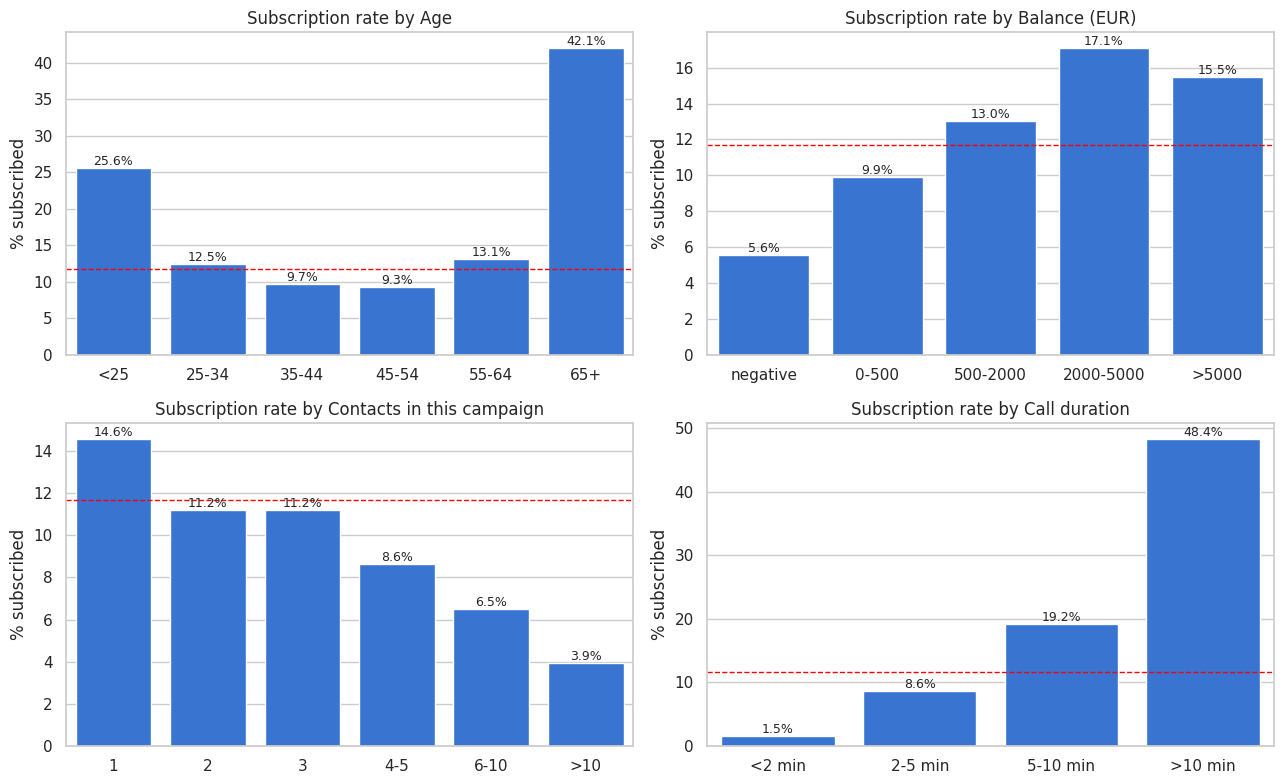

Age: highest rate = 65+ (42.1%), lowest rate = 45-54 (9.3%)
Balance (EUR): highest rate = 2000-5000 (17.1%), lowest rate = negative (5.6%)
Contacts in this campaign: highest rate = 1 (14.6%), lowest rate = >10 (3.9%)
Call duration: highest rate = >10 min (48.4%), lowest rate = <2 min (1.5%)
Previously contacted: 23.1% subscribed | never contacted before: 9.2% subscribed


In [327]:
groups = {
    "Age": pd.cut(df["age"], [17, 24, 34, 44, 54, 64, 100], labels=["<25", "25-34", "35-44", "45-54", "55-64", "65+"]),
    "Balance (EUR)": pd.cut(df["balance"], [-10000, -1, 500, 2000, 5000, 200000],
                            labels=["negative", "0-500", "500-2000", "2000-5000", ">5000"]),
    "Contacts in this campaign": pd.cut(df["campaign"], [0, 1, 2, 3, 5, 10, 100], labels=["1", "2", "3", "4-5", "6-10", ">10"]),
    "Call duration": pd.cut(df["duration"], [-1, 120, 300, 600, 6000], labels=["<2 min", "2-5 min", "5-10 min", ">10 min"]),
}

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (name, groups_) in zip(axes.ravel(), groups.items()):
    rate = df.groupby(groups_, observed=True)["y_num"].mean() * 100
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="#1f6feb")
    ax.bar_label(ax.containers[0], fmt="%.1f%%", fontsize=9)
    ax.axhline(overall, color="red", ls="--", lw=1)
    ax.set_title(f"Subscription rate by {name}"); ax.set_xlabel(""); ax.set_ylabel("% subscribed")
plt.tight_layout(); plt.show()

# plain-language sentences
for name, groups_ in groups.items():
    rate = df.groupby(groups_, observed=True)["y_num"].mean() * 100
    print(f"{name}: highest rate = {rate.idxmax()} ({rate.max():.1f}%), lowest rate = {rate.idxmin()} ({rate.min():.1f}%)")

contacted = df[df["pdays"] != -1]["y_num"].mean() * 100
never = df[df["pdays"] == -1]["y_num"].mean() * 100
print(f"Previously contacted: {contacted:.1f}% subscribed | never contacted before: {never:.1f}% subscribed")

**How to read it:**
- **Age:** the youngest and the oldest groups subscribe more than the middle-aged groups (U-shape).
- **Balance:** customers with a higher balance subscribe more often; customers with a negative balance subscribe least.
- **Contacts in this campaign:** the more often a customer is called, the lower the success rate: repeated calls do not help.
- **Call duration:** long calls almost always end in a subscription. **But the length of a call is only known after the call**, so it cannot be used to decide *whom to call*. We will exclude `duration` when we build models (data leakage).

## 1.5 Categorical variables vs. subscription

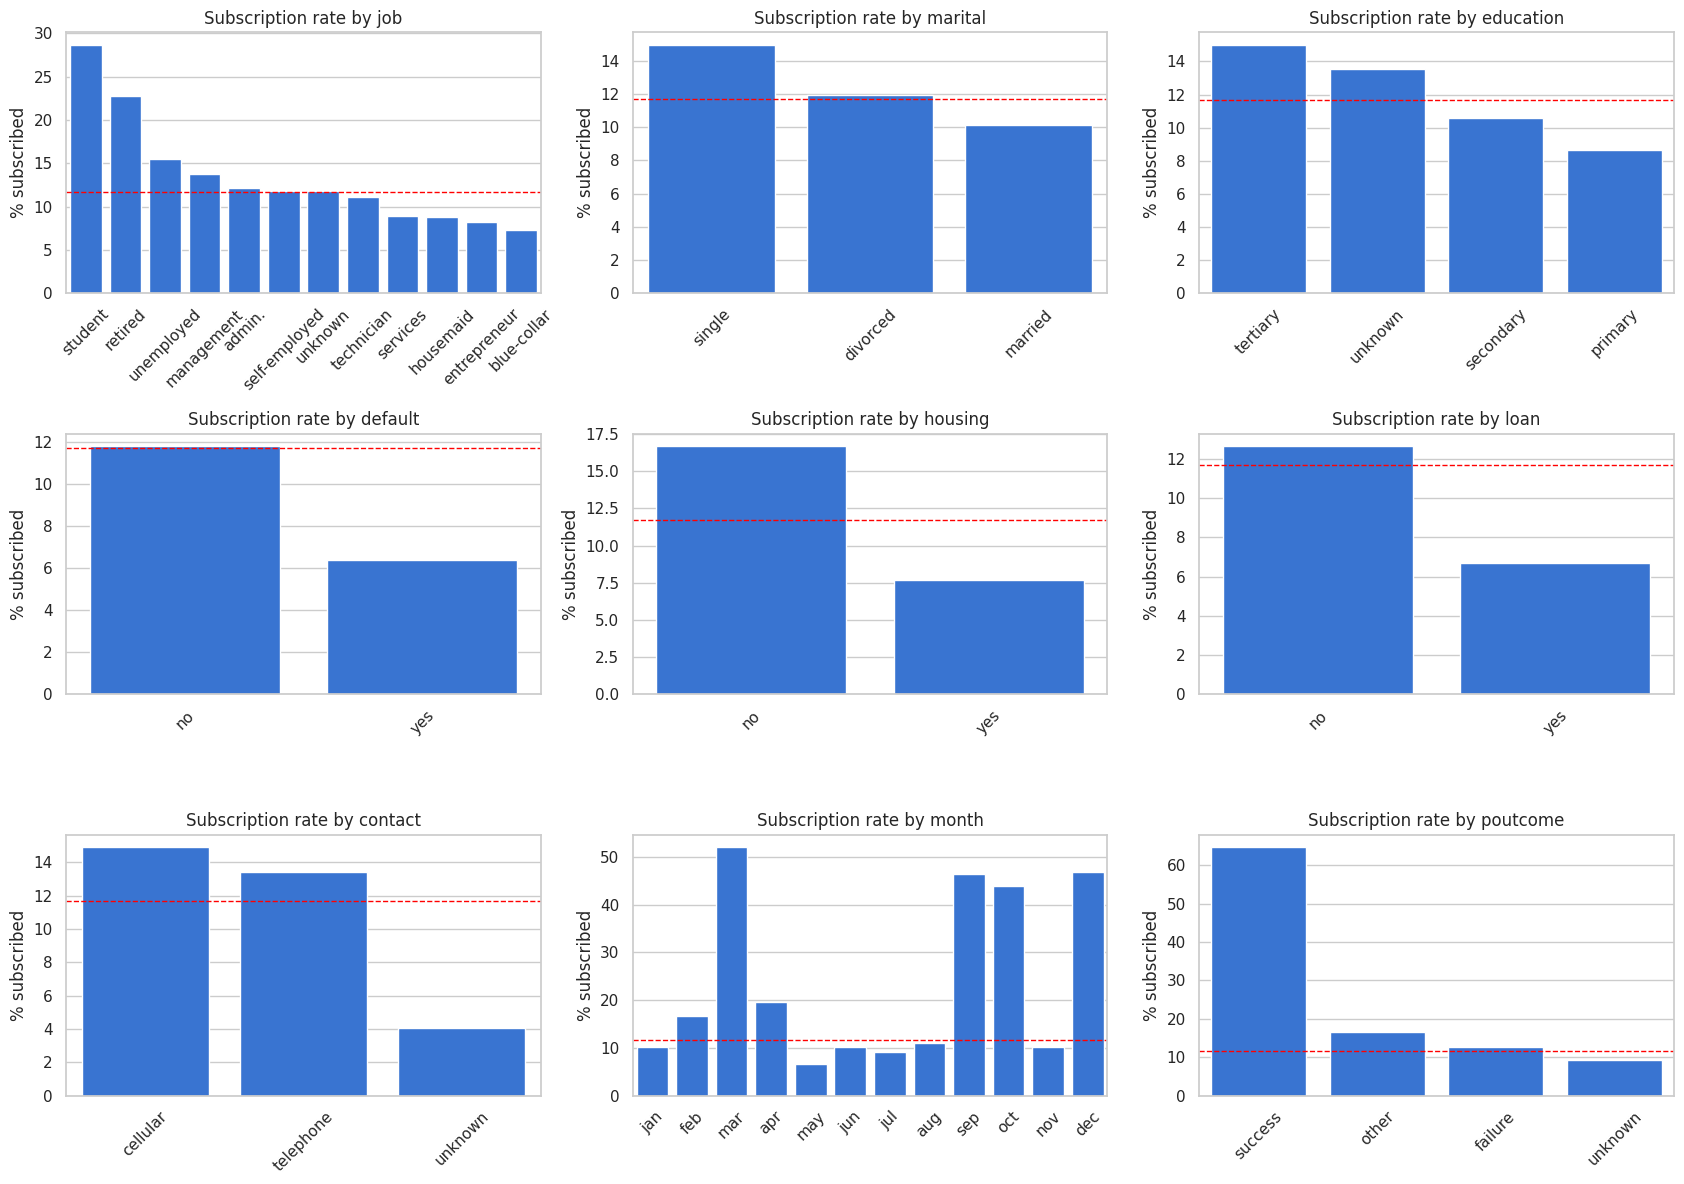

In [328]:
fig, axes = plt.subplots(3, 3, figsize=(17, 12))
month_order = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
for ax, col in zip(axes.ravel(), cat_cols):
    rate = df.groupby(col)["y_num"].mean() * 100
    rate = rate.reindex(month_order) if col == "month" else rate.sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax, color="#1f6feb")
    ax.axhline(overall, color="red", ls="--", lw=1)
    ax.set_title(f"Subscription rate by {col}"); ax.set_xlabel(""); ax.set_ylabel("% subscribed")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

The charts illustrate how subscription rates vary across different customer characteristics and campaign-related variables. Among job categories, students and retired customers show the highest subscription rates, at approximately 28% and 23%, respectively, while blue-collar workers and entrepreneurs have lower rates. Regarding marital status, single customers have the highest subscription rate, followed by divorced and married customers. Customers with tertiary education also show higher subscription rates than those with secondary or primary education.

The financial indicators reveal that customers without existing credit in default, housing loans, or personal loans tend to have higher subscription rates than those with these financial commitments. Subscription rates also differ by contact method: cellular and telephone contacts perform better than contacts recorded as unknown.

Month and previous campaign outcome show particularly strong differences. March, September, October, and December have notably high subscription rates, although these results should be interpreted cautiously where the number of observations is small. Customers whose previous campaign outcome was a success have by far the highest subscription rate, at approximately 64%, compared with substantially lower rates for other outcomes.

Overall, the charts suggest that customer characteristics, financial circumstances, contact information, campaign timing, and previous campaign outcomes are associated with subscription behaviour. These patterns can inform feature engineering and model development, although the relationships shown are descriptive and do not establish causation.

**Which variable separates the customers most?** For every variable we compare its best and its worst group (groups with fewer than 100 customers are ignored). A **big gap** means the variable matters.

In [329]:
rows = []
for col in cat_cols:
    t = df.groupby(col)["y_num"].agg(customers="count", rate="mean")
    t = t[t["customers"] >= 100]
    t["rate"] *= 100
    rows.append({"variable": col, "best group": t["rate"].idxmax(), "best rate %": t["rate"].max(),
                 "worst group": t["rate"].idxmin(), "worst rate %": t["rate"].min()})
gap = pd.DataFrame(rows)
gap["gap (points)"] = gap["best rate %"] - gap["worst rate %"]
gap = gap.sort_values("gap (points)", ascending=False).set_index("variable").round(1)
display(gap)

,best group,best rate %,worst group,worst rate %,gap (points)
variable,,,,,
poutcome,success,64.7,unknown,9.2,55.6
month,mar,52.0,may,6.7,45.3
job,student,28.7,blue-collar,7.3,21.4
contact,cellular,14.9,unknown,4.1,10.8
housing,no,16.7,yes,7.7,9.0
education,tertiary,15.0,primary,8.6,6.4
loan,no,12.7,yes,6.7,6.0
default,no,11.8,yes,6.4,5.4
marital,single,14.9,married,10.1,4.8


The table highlights substantial differences in subscription rates across customer characteristics and campaign-related variables. The largest gap is observed for previous campaign outcome (poutcome): customers whose previous campaign was successful have a subscription rate of 64.7%, compared with only 9.2% for customers with an unknown outcome, a difference of 55.6 percentage points.


Campaign timing also shows considerable variation. March has the highest monthly subscription rate at 52.0%, while May has the lowest at 6.7%. Regarding job categories, students achieve the highest subscription rate (28.7%), whereas blue-collar workers have the lowest (7.3%).


Other notable differences relate to contact method and financial circumstances. Customers contacted by cellular phone have a higher subscription rate than those with an unknown contact method. Customers without housing loans or personal loans also show higher subscription rates than those with these loans. Similarly, tertiary-educated and single customers have higher subscription rates than primary-educated and married customers, respectively.


Overall, the findings suggest that previous campaign outcomes, campaign month, and job category exhibit the largest differences in subscription rates. These variables may therefore be useful for feature selection and feature engineering in the predictive models. However, the observed differences are descriptive associations and do not necessarily imply causal relationships.

## 1.6 Months: number of calls vs. success rate

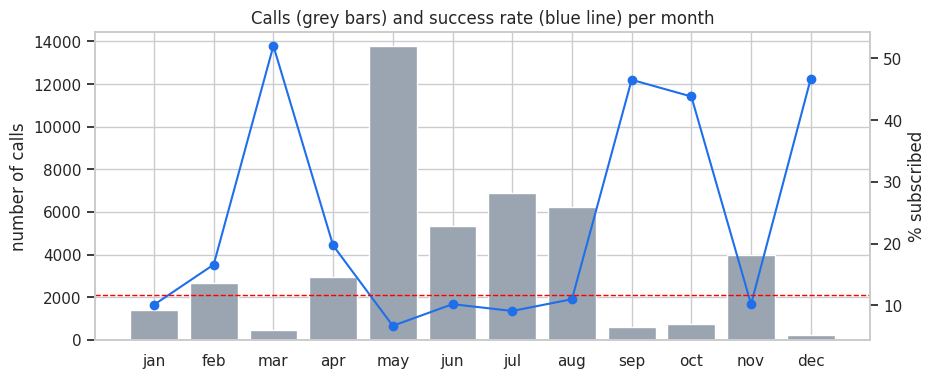

Most calls: may (13766 calls, success rate 6.7%)
Best success rate: mar (52.0%, only 477 calls)


In [330]:
m = df.groupby("month")["y_num"].agg(calls="count", rate="mean").reindex(month_order)
m["rate"] = (m["rate"] * 100).round(1)

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(m.index, m["calls"], color="#9aa5b1"); ax1.set_ylabel("number of calls")
ax2 = ax1.twinx(); ax2.plot(m.index, m["rate"], color="#1f6feb", marker="o"); ax2.set_ylabel("% subscribed")
ax2.axhline(overall, color="red", ls="--", lw=1); ax2.grid(False)
plt.title("Calls (grey bars) and success rate (blue line) per month"); plt.show()

print(f"Most calls: {m['calls'].idxmax()} ({m['calls'].max()} calls, success rate {m.loc[m['calls'].idxmax(), 'rate']}%)")
print(f"Best success rate: {m['rate'].idxmax()} ({m['rate'].max()}%, only {m.loc[m['rate'].idxmax(), 'calls']} calls)")

**How to read it:**
- **poutcome** (result of the previous campaign): customers who subscribed last time are by far the most likely to subscribe again.
- **month:** the bank made most calls in May, but May has one of the lowest success rates. March, September, October and December have very high success rates but few calls.
- **job:** students and retired customers subscribe most; blue-collar workers least.
- **housing / loan:** customers *without* a housing loan or personal loan subscribe more often.
- **contact:** calls to a mobile phone (*cellular*) work better than calls to a landline (*telephone*).
- Variables with a small gap (for example `default` or `marital`) matter less.

The chart illustrates the monthly distribution of calls (grey bars) and the subscription success rate (blue line). The number of calls varies considerably throughout the year, with May recording the highest call volume, followed by July, August, and June. However, a higher number of calls does not necessarily correspond to a higher subscription success rate. March shows the highest success rate at approximately 52%, despite having relatively few calls, while May records the lowest rate at around 7%, despite having the highest call volume. September, October, and December also show relatively high success rates, at approximately 46%, 44%, and 46%, respectively. The red dashed line represents a reference success rate of approximately 12%.



## 1.7 Correlation and summary

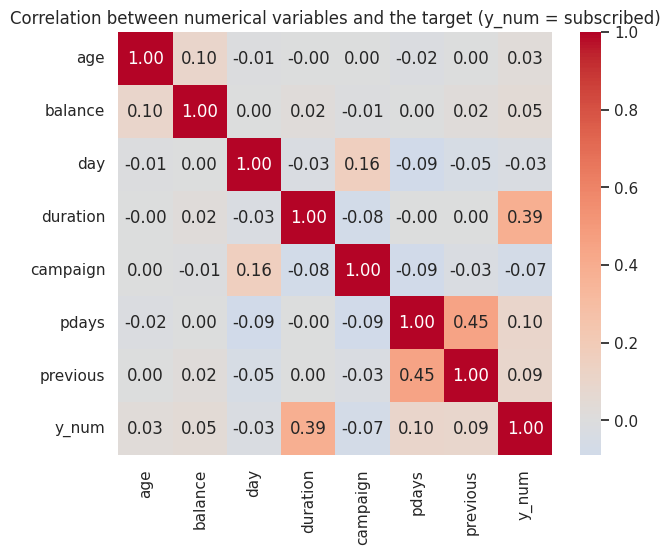

Correlation with subscription (strongest first):
duration    0.39
pdays       0.10
previous    0.09
campaign   -0.07
balance     0.05
day        -0.03
age         0.03


In [331]:
corr = df[num_cols + ["y_num"]].corr().round(2)
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numerical variables and the target (y_num = subscribed)"); plt.show()

print("Correlation with subscription (strongest first):")
print(corr["y_num"].drop("y_num").sort_values(key=abs, ascending=False).to_string())

The strongest positive correlation with the target is observed for duration (0.39), suggesting that longer calls are associated with a higher likelihood of subscription. However, call duration may not be known before contacting a customer, so it should be excluded from a model intended for pre-call predictions.

The remaining numerical variables show relatively weak correlations with the target. pdays has a small positive correlation (0.10), followed by previous (0.09), balance (0.05), and age (0.03). In contrast, campaign (-0.07) and day (-0.03) show weak negative correlations. A moderate positive correlation of 0.45 exists between pdays and previous, while most other pairs of numerical predictors have correlations close to zero.

Overall, the matrix suggests that no single numerical variable, apart from duration, has a strong linear relationship with subscription. Nevertheless, weak individual correlations do not necessarily mean that a variable has no predictive value, as relationships may be nonlinear or depend on interactions with other features.

In [332]:

top3 = gap.head(3).index.tolist()
print(f"1. {overall:.1f}% of the customers subscribed (imbalanced data).")
print(f"2. The categorical variables with the biggest differences between groups: {', '.join(top3)}.")
print(f"3. Best month: {m['rate'].idxmax()} ({m['rate'].max()}%). Busiest month: {m['calls'].idxmax()} (success rate {m.loc[m['calls'].idxmax(), 'rate']}%).")
print(f"4. Previously contacted customers subscribed {contacted:.1f}% of the time, never-contacted customers {never:.1f}%.")
print("5. 'duration' is strongly related to success but is only known after the call -> exclude it from models.")

1. 11.7% of the customers subscribed (imbalanced data).
2. The categorical variables with the biggest differences between groups: poutcome, month, job.
3. Best month: mar (52.0%). Busiest month: may (success rate 6.7%).
4. Previously contacted customers subscribed 23.1% of the time, never-contacted customers 9.2%.
5. 'duration' is strongly related to success but is only known after the call -> exclude it from models.


### 1.7.1 Summary and consequences for the next steps
| Finding | What we do next |
|---|---|
| Only ~12% subscribed | use precision, recall and F1, not only accuracy |
| `duration` is known only after the call | exclude it from the models (data leakage) |
| "unknown" text and `pdays = -1` are codes for missing information | keep "unknown" as a category; create a "contacted before" flag instead of using `pdays = -1` as a number |
| `balance`, `campaign` have a long right tail | consider a log transform or cap extreme values |
| Age, month and previous outcome have clear patterns | consider age groups |
| Weak variables (small gap, e.g. `default`) | can be excluded or kept; models will give them little weight |

# 2 Prepare the data




**Inspect Columns and their values**

This section provides information of each columns considering:

- What the columns represents: *name*
- Which type of data it includes: *dtype*
- Number of unique values: Distinct *values*
- Example values: instance from the *columns*

In [333]:

# data (as pandas dataframes)
X =  df.drop(columns=["y", "y_num"])
y =  df["y_num"]


dataset = pd.concat([X, y], axis=1)


display(dataset.head())
dataset.info()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y_num
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y_num      45211 non-null  int64 
dtypes: int64(8), object(9)
memory usage: 5.9+ MB


In [334]:
# Column overview

column_info = pd.DataFrame({
    "Column": X.columns,
    "Data Type": X.dtypes.values,
    "Unique Values": [X[col].nunique() for col in X.columns],
    "Example Values": [
        X[col].dropna().unique()[:10].tolist()
        for col in X.columns
    ]
})

column_info

,Column,Data Type,Unique Values,Example Values
0,age,int64,77,"[58, 44, 33, 47, 35, 28, 42, 43, 41, 29]"
1,job,object,12,"[management, technician, entrepreneur, blue-co..."
2,marital,object,3,"[married, single, divorced]"
3,education,object,4,"[tertiary, secondary, unknown, primary]"
4,default,object,2,"[no, yes]"
5,balance,int64,7168,"[2143, 29, 2, 1506, 1, 231, 447, 121, 593, 270]"
6,housing,object,2,"[yes, no]"
7,loan,object,2,"[no, yes]"
8,contact,object,3,"[unknown, cellular, telephone]"
9,day,int64,31,"[5, 6, 7, 8, 9, 12, 13, 14, 15, 16]"


## 2.1 Analysis of the columns

**Analysis of the columns:**

UCI Bank Marketing dataset has 16 features and 1 target.

The variables are distinguished between three groups:

* Bank client data
* Other attributes
* Target variable

A description of each feature with the decision to keep or discard it, together with the subsequent transformation to fit the machine learning model is provided.

**Bank client data:**


*   **age**: it represents the age of the client (*numerical*) -> **Kept** -> **StandardScaler**
*   **job**: it represents the type of job the client does (*categorical*) -> **Kept** -> **One-Hot**
*   **marital**: it represents the marital status of the client (*categorical*) -> **Kept** -> **One-Hot**
*   **education**: it represents the education pursued by the client (*categorical*) -> **Kept**  -> **One-Hot**
*  **default**: it represents if the client has credit in default (*binary*) -> **Kept** -> **Numerical**
* **housing**: it represents if the client has housing loan (*binary*) -> **Kept** -> **0/1**
* **loan**: it represents if the client has personal loan (*binary*) -> **Kept** -> **0/1**


**Other attributes:**

* **campaign**: it represents the number of contacts performed during this campaign and for this client (*numerical*) -> **Kept** -> **StandardScaler**
* **pdays**: it represents the number of days that passed after the client was last contacted from a previous campaign (*numerical*) -> **Kept** -> **StandardScaler**
* **previous**: it represents the number of contacts performed before this campaign and for this client (*numerical*) -> **Kept** -> **Numerical**
* **poutcome**: it represents the outcome of the previous marketing campaign (*categorical*) -> **Kept** -> **One-Hot**

**Target variable:**

* **y**: it represents the target column, if the client subscribed a term deposit (*binary*) -> **0/1**


**Discarded**
* **contact**: it represents contact communication type (*categorical*) -> **Discarded** -> from an EDA it could be confirmed that it does not add any additional value to the prediction of the target variable
* **day**: it represents the last contact day of the month (*numerical*) -> **Discarded** -> discarded because it may add complexity on the model and it might not predict if a client may subscribed or not based on how many days have passed since the last call.
* **month**: it represents the last contact month of the year (*categorical*) -> **Discarded** -> even though the EDA shows that most of the clients subscribed a term deposit in may, it can introduce data leakage, labelling as yes each potential clients that is called in this month. To reduce potential misrappresentation of the client behaviour, it has been discarded.
* **duration**: it represents the last contact duration, in seconds (*numerical*) -> **Discarded** -> the duration of the call can indirectly represent the outcome of the target variable, since hypothetically, a last contact duration that is long could mean the client subscribed a term deposit

# 3 Machine Learning Models

##3.1 Machine Learning Models

This section presents three machine learning models applied on the dataset, starting from a baseline model such as logistic regression (that trying to map a linear relationship between the features), a XGBoost (to map non-relationship ) and Random Forest.

The decision to use these three algorithms is to apply an incremental approach, to test and measure the results obtained starting from a simple model (logistic regression) and then adding complexity (XGBoost and Random Forest).

In this section, minimal parameter configuration is applied, to have a baseline evaluation of the algorithms trained.

### 3.1.1 Data Preprocessing:

First of all, the features that have been identified as not useful, are dropped from the dataset. After that, data preprocessing is applied on the dataset.

* **Label encoder** converts binary values such as 'yes' or 'no', into 1 and 0.
* **Standard scaler** changes the scale of numerical values, scaling the numbers so that the mean is 0 and the standard deviation is 1.
* **One hot encoding** converts categorical features into numerical binary values, where 1 represents the presence of the value in the category and 0 is the absence of the value in another category.

## 3.2 Logistic Regression (Baseline model)

Logistic Regression is used to predict whether a bank client subscribes to a term deposit (`yes` or `no`). This section follows a consistent evaluation sequence: (1) establish a baseline, (2) add the two features defined by the group, (3) tune selected model parameters, and (4) compare all models. The same stratified train-test split is used throughout. In line with the group’s modelling approach, `contact`, `day_of_week`, `month`, and `duration` are excluded; in particular, `duration` is only known after a call and could cause target leakage.




The baseline uses the original predictors after the agreed exclusions. Numeric features are standardized and categorical features are one-hot encoded inside a pipeline. The confusion matrix shows the types of correct and incorrect predictions, while the ROC curve and ROC-AUC assess discrimination across thresholds.

In [335]:
# 3.2.1 Baseline Logistic Regression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay
)

# Create one fixed split so each model is evaluated on the same observations.
X_lr = X.copy()
y_lr = y.copy().astype(int)
X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(
    X_lr, y_lr, test_size=0.40, random_state=42, stratify=y_lr
)

columns_to_drop_lr = ['contact', 'day_of_week', 'month', 'duration']
X_train_base = X_train_lr.drop(columns=columns_to_drop_lr, errors='ignore')
X_test_base = X_test_lr.drop(columns=columns_to_drop_lr, errors='ignore')

num_features_base = ['age', 'balance', 'campaign', 'pdays', 'previous']
cat_features_base = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'poutcome']
preprocessor_base = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_features_base),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features_base)
])

baseline_lr = Pipeline(steps=[
    ('preprocessor', preprocessor_base),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])
baseline_lr.fit(X_train_base, y_train_lr)
baseline_pred = baseline_lr.predict(X_test_base)
baseline_prob = baseline_lr.predict_proba(X_test_base)[:, 1]
baseline_auc = roc_auc_score(y_test_lr, baseline_prob)

print('BASELINE LOGISTIC REGRESSION')
print(f'Accuracy: {accuracy_score(y_test_lr, baseline_pred):.4f}')
print(f'ROC-AUC:  {baseline_auc:.4f}')
print(classification_report(y_test_lr, baseline_pred, target_names=['no', 'yes'], zero_division=0))


BASELINE LOGISTIC REGRESSION
Accuracy: 0.8941
ROC-AUC:  0.7336
              precision    recall  f1-score   support

          no       0.90      0.99      0.94     15969
         yes       0.70      0.16      0.27      2116

    accuracy                           0.89     18085
   macro avg       0.80      0.58      0.60     18085
weighted avg       0.88      0.89      0.86     18085



The baseline Logistic Regression model achieved an accuracy of 89.41% and a ROC-AUC score of 0.7336, indicating a reasonable ability to distinguish between customers who subscribe to a term deposit and those who do not.

However, the classification report reveals a substantial difference between the two classes. The model performs very well when predicting customers who do not subscribe, achieving a recall of 99% and an F1-score of 0.94. In contrast, for customers who subscribe, the recall is only 16%, with an F1-score of 0.27. Although the precision for this class is 70%, the model identifies only a small proportion of actual subscribers.

This limitation is partly related to the imbalanced target variable, as non-subscribers significantly outnumber subscribers in the dataset. Consequently, the high overall accuracy does not fully reflect the model's ability to identify potential subscribers.

###3.2.1 Confusion Matrix

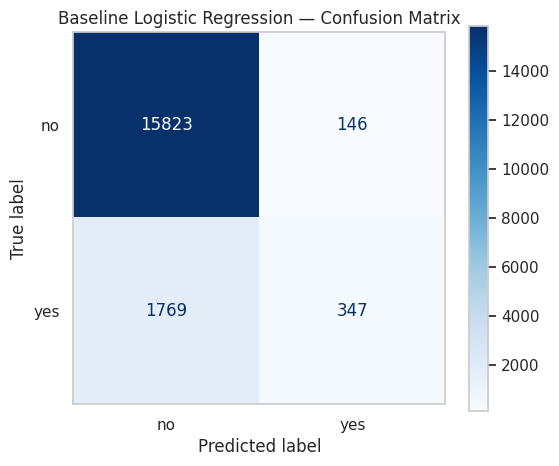

In [336]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Plot just the Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_lr,
    baseline_pred,
    display_labels=['no', 'yes'],
    cmap='Blues',
    values_format='d',
    ax=ax
)
ax.set_title('Baseline Logistic Regression — Confusion Matrix')
ax.grid(False)
plt.show()

The confusion matrix shows that the baseline Logistic Regression model correctly classified **15,823 non-subscribers** and **347 subscribers**. However, it incorrectly classified 146 non-subscribers as subscribers and failed to identify 1,769 actual subscribers. This indicates that the model is much better at identifying customers who do not subscribe than those who do.


###3.2.2 ROC Curve

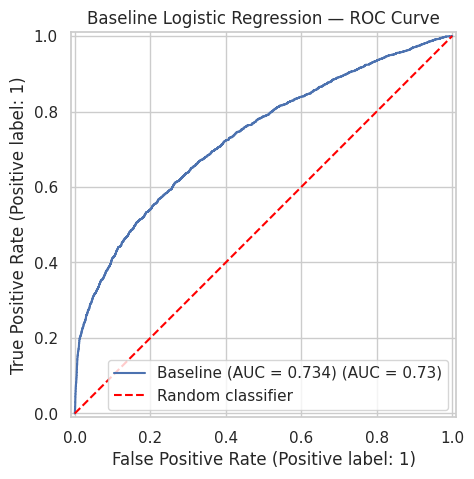

In [337]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# Plot just the ROC Curve
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(
    y_test_lr,
    baseline_prob,
    ax=ax,
    name=f'Baseline (AUC = {baseline_auc:.3f})'
)
ax.plot([0, 1], [0, 1], linestyle='--', color='red', label='Random classifier')
ax.set_title('Baseline Logistic Regression — ROC Curve')
ax.legend(loc='lower right')
plt.show()

The Receiver Operating Characteristic (ROC) curve evaluates the baseline Logistic Regression model's ability to distinguish between customers who subscribe to a term deposit and those who do not. The model achieves a ROC-AUC score of 0.734, indicating a reasonable ability to differentiate between the two classes. The blue curve lies above the diagonal line, which represents a random classifier, showing that the model performs better than random guessing. However, its performance is not optimal, suggesting that there is room for improvement. Therefore, feature engineering and parameter tuning will be applied to investigate whether the model's discriminatory ability can be improved.

## 3.3 XGBoost

In this section the algorithm XGBoost is applied.
XGBoost (Extreme Gradient Boosting) is a supervised machine learning algorithm based on the Gradient Boosting technique, which combines multiple decision trees to produce accurate predictions.

It is widely used for classification and regression tasks, particularly when working with structured or tabular datasets.

Unlike Random Forest, which builds multiple decision trees independently and combines their predictions, XGBoost constructs decision trees sequentially, with each new tree attempting to correct the errors made by the previous ones.

The algorithm works by minimizing a loss function through gradient-based optimization. During each iteration, a new decision tree is added to improve the model's overall predictive performance.

The technique used for this split is to divide the dataset with the following percentage:

60% of the dataset to the training set and 40% of the dataset to the test set.

In this part of the analysis, the validation set is not created, properly to see the results obtained from the model with a baseline configuration.

The model XGBoost is applied with the following paramenters:
* **max_depth** = 5  -> It controls the maximum depth of each decision tree.
* **learning_rate**=0.3 -> It controls the contribution of each new tree.
* **n_estimators**=150 -> It determines the number of boosting rounds.
* **objective**='binary:logistic' -> It specifies binary classification with logistic loss.
* **random_state**=42 -> It controls randomness to improve reproducibility.

In [338]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.40, random_state=42)

# Discarding the features we don't need
columns_to_drop = ['contact', 'day_of_week', 'month', 'duration']
X_train_clean = X_train.drop(columns=columns_to_drop, errors='ignore')
X_test_clean = X_test.drop(columns=columns_to_drop, errors='ignore')

# Conversion of the target column from 'yes' / 'no' to '1' and '0' (LabelEncoder)
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train.values.ravel())
y_test_encoded = le.transform(y_test.values.ravel())

# Definition of numerical features and categorical features
num_features = ['age', 'balance', 'campaign', 'pdays', 'previous']
cat_features = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'poutcome']

# Preprocessing of the features (applying StandardScaler and OneHotEncoder)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
    ])

# Transformation
X_train_processed = preprocessor.fit_transform(X_train_clean)
X_test_processed = preprocessor.transform(X_test_clean)

# Training XGBoost
bst = xgb.XGBClassifier(
    max_depth=5,
    learning_rate=0.3,
    n_estimators=150,
    objective='binary:logistic',
    random_state=42
)

bst.fit(
    X_train_processed,
    y_train_encoded,
    eval_set=[(X_test_processed, y_test_encoded)],
    verbose=False
)

# Prediction on the test set using X_test
preds = bst.predict(X_test_processed)

# Evaluation of the model performance against the prediction with y_test
print(f"Accuracy on Test Set: {accuracy_score(y_test_encoded, preds):.4f}\n")
print(classification_report(y_test_encoded, preds, target_names=['no', 'yes']))

Accuracy on Test Set: 0.8887

              precision    recall  f1-score   support

          no       0.90      0.98      0.94     15984
         yes       0.57      0.18      0.27      2101

    accuracy                           0.89     18085
   macro avg       0.73      0.58      0.61     18085
weighted avg       0.86      0.89      0.86     18085



The results obtained from the XGBoost showed an accuracy of 89%. Since the dataset is imbalanced, we need to analyze Precision and Recall for each target values, to have a more clear picture of the performance of the model.

With a recall of 98% the model, from all the clients that haven't suscribed to a term deposit, correctly identified 98% of them. Futhermore the precision is 90% meaning that the model, from all the sample predicted as 'no', identified 90% of clients that haven't suscribed to a term deposit.

If we look at the 'yes' class, the precision is quite low 57% meaning that of the samples predicted as 'yes', 57% have subscribed to a term deposit. Futhermore with a recall of 18% it means the model, from all the clients that have subscribed to a term deposit, identified just the 18% of them.



### 3.3.1 Confusion Matrix


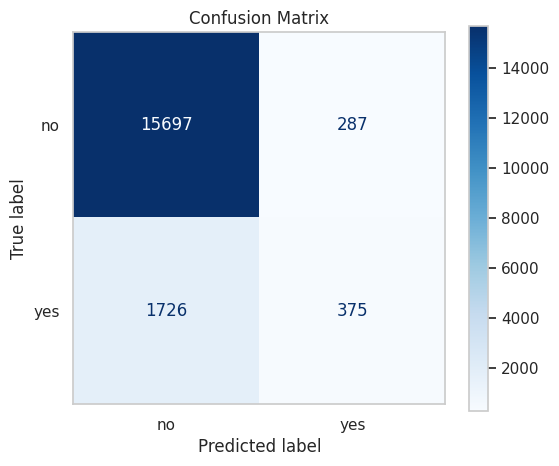

In [339]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Plot Confusion Matrix
cm = confusion_matrix(y_test_encoded, preds)
fig, ax = plt.subplots(figsize=(6, 5))
disp_cm = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['no', 'yes'])
disp_cm.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('Confusion Matrix')
ax.grid(False)
plt.show()

The confusion matrix gives us the situation from the perspective of the predicted datapoints against the ground truth.

Starting from the top left, the model correctly predicted 15697 samples as no and it confused 287 clients that incorrecly predicted as yes but eventually they haven't subscribed to a term deposit. Furthermore, it predicted 1726 clients as no but they actually subscribed to a term deposit.

If we look at the yes class, the model correctly predicted 375 clients that subscribed evetually to a term deposit but it wrongly predicted 287 clients as yes when they haven't subscribed eventually to a term deposit.

### 3.3.2 ROC Curve


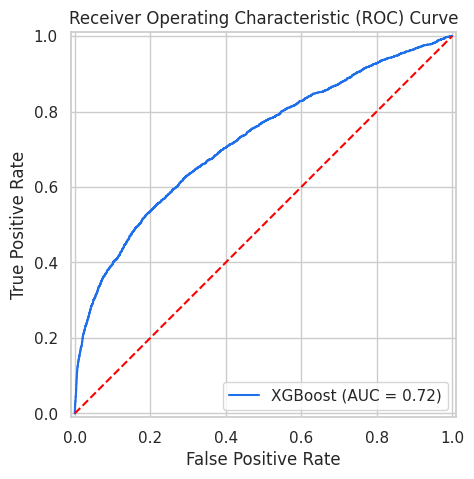

In [293]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, RocCurveDisplay

# 2. Plot ROC Curve
y_probs = bst.predict_proba(X_test_processed)[:, 1]
fpr, tpr, _ = roc_curve(y_test_encoded, y_probs)
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(6, 5))
disp_roc = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name='XGBoost')
disp_roc.plot(ax=ax, color='#1f6feb')
ax.plot([0, 1], [0, 1], color='red', linestyle='--')
ax.set_title('Receiver Operating Characteristic (ROC) Curve')
plt.show()

The ROC curve put in relation the TPR that identifies the percentage of true positives over the true positive and false negative and the FPR that identifies the percentage of false positive over true negative and false positive.
It shows from different threshold, the proportion of both metrics. The closer the ROC Curve is to the diagonal line, the lower the model's ability to distinguish between positive and negative classes. A curve following the diagonal indicates performance equivalent to random guessing in terms of class discrimination, corresponding to an AUC of 0.5. The closer the ROC Curve is to the upper-left corner, the better the model's ability to distinguish between the two classes, as it achieves a higher True Positive Rate while maintaining a lower False Positive Rate.

Since the AUC is 0.72, the classifier demonstrates a moderate ability to distinguish between positive and negative classes. Specifically, it has a 72% probability of assigning a higher predicted probability to a randomly selected customer who subscribed to a term deposit than to one who did not.

## 3.4 Random Forest Classifier
The third Classification used in this project is the Random Forest Classifier. At the begin we set as Threshold the value of 0.30. Later on, we'll see how the algorithm's performance changes as this parameter varies.

The model uses a preprocessing pipeline to handle the different types of variables in the dataset. Numerical variables, such as age and balance, are kept unchanged, while categorical variables, such as job, marital status and education, are converted into numerical values through One-Hot Encoding.

Parameter used in the algorithm are:
- `handle_unknown = "ignore"` parameter ensures that the model can still make predictions if it encounters a category that was not present in the training set;
- `n_estimators = 300` is the number of the decision trees in the Random Forest, which improves the stability of the predictions;
- `min_samples_leaf = 3` prevents the trees from creating leaves with very few observations, helping to reduce overfitting;
- `random_state = 42` makes the results reproducible (ensures that randomized operations, like splitting data into training and test sets, produce the exact same result every time you run the code);
- `n_jobs = -1` allows the model to use all available processor cores and reduce training time.

Later on in the script we've set the value of threshold equal to 0.30. This value is a cut-off that converts a continuous score or probability into a discrete action or category.

In [294]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Identify numerical and categorical variables
numerical_features = X_train.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X_train.select_dtypes(include=["object", "category"]).columns

# Preprocessing:
# - numerical variables are kept unchanged
# - categorical variables are converted using One-Hot Encoding
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Define the Random Forest model
random_forest = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Create the full pipeline
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", random_forest)
])

# Train the model
rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  Index(['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous'], dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome'],
      dtype='object'))])),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        min_samples_leaf=3, n_estimators=300,
                                        n_jobs=-1, random_state=42))])

In [295]:
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score, roc_auc_score


y_prob_rf = rf_pipeline.predict_proba(X_test)[:, 1]


y_test_binary = y_test


threshold = 0.30


y_pred_binary = (y_prob_rf >= threshold).astype(int)


print("Random Forest Classification Report:\n")
print(classification_report(
    y_test_binary,
    y_pred_binary,
    target_names=["No subscription", "Subscription"]
))

print("Precision:", round(precision_score(y_test_binary, y_pred_binary), 3))
print("Recall:", round(recall_score(y_test_binary, y_pred_binary), 3))
print("F1-score:", round(f1_score(y_test_binary, y_pred_binary), 3))
print("ROC-AUC:", round(roc_auc_score(y_test_binary, y_prob_rf), 3))

Random Forest Classification Report:

                 precision    recall  f1-score   support

No subscription       0.98      0.83      0.90     15984
   Subscription       0.41      0.90      0.57      2101

       accuracy                           0.84     18085
      macro avg       0.70      0.87      0.73     18085
   weighted avg       0.92      0.84      0.86     18085

Precision: 0.414
Recall: 0.9
F1-score: 0.567
ROC-AUC: 0.93


The Random Forest model achieved an ROC-AUC of 0.93, indicating a strong ability to distinguish between customers who subscribe and those who do not.

The model performs particularly well for the “No subscription” class, with an F1-score of 0.90. For the “Subscription” class, the recall is high (0.90), meaning that the model correctly identifies most customers who are likely to subscribe. However, precision is lower (0.414), so a considerable number of customers predicted as subscribers do not actually subscribe. This result is consistent with the use of class_weight="balanced" and a relatively low classification threshold: the model gives priority to reducing missed subscription opportunities, at the cost of more false positives. Therefore, the model is suitable for a campaign where reaching potential subscribers is more important than limiting the total number of contacts.

### 3.4.1 Confusion Matrix


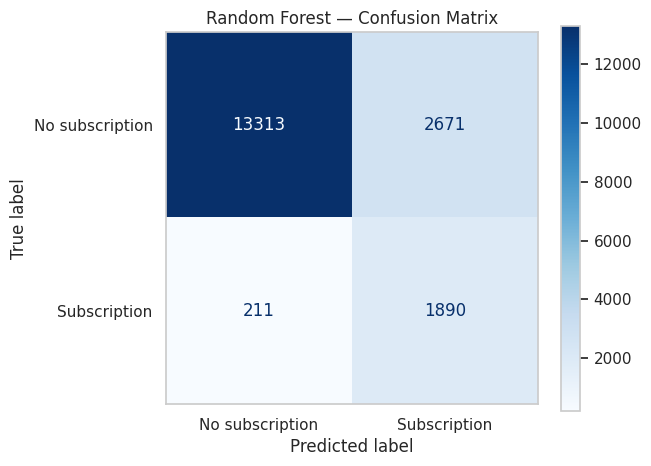

In [296]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_binary,
    y_pred_binary,
    display_labels=["No subscription", "Subscription"],
    cmap="Blues",
    values_format="d",
    ax=ax
)
ax.set_title("Random Forest — Confusion Matrix")
ax.grid(False)
plt.show()

The confusion matrix confirms that the model is effective at identifying actual subscribers: out of 2.102 (211 + 1891) customers who subscribed, 1.891 were correctly classified as “Subscription”, while only 211 were missed. This explains the high recall obtained for the positive class. However, 2.671 customers who did not subscribe were incorrectly predicted as subscribers. These false positives are responsible for the lower precision value.

Overall, the model is appropriate when the bank prefers to contact more potentially interested customers and accepts some unnecessary calls in return for missing fewer real subscription opportunities.

### 3.4.2 ROC Curve


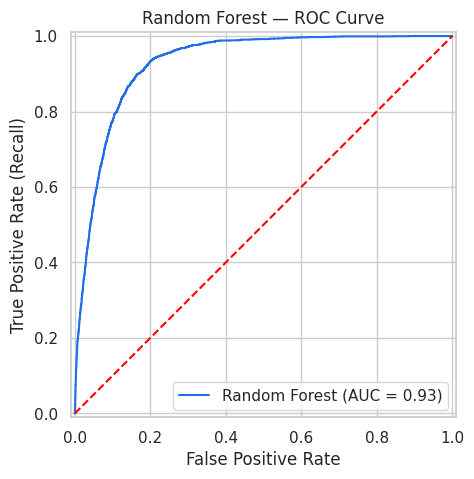

In [297]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, RocCurveDisplay


fpr, tpr, thresholds = roc_curve(y_test_binary, y_prob_rf)
roc_auc = auc(fpr, tpr)


fig, ax = plt.subplots(figsize=(6, 5))
disp_roc = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name='Random Forest')
disp_roc.plot(ax=ax, color='#1f6feb')
ax.plot([0, 1], [0, 1], color='red', linestyle='--', label='Random classifier')
ax.set_title('Random Forest — ROC Curve')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate (Recall)')
plt.show()

The ROC curve shows that the Random Forest model has strong discriminatory performance. The curve is clearly above the diagonal line representing a random classifier and remains close to the top-left corner of the graph. This indicates that the model can achieve a high true positive rate while keeping the false positive rate relatively low. The AUC value of 0.930 confirms this result: since it is close to 1, the model is very effective at distinguishing between customers who are likely to subscribe and those who are not.

The final classification threshold should still be selected according to the bank's objective, since the ROC curve does not determine the best balance between false positives and false negatives on its own.

# 4 Compare different models


## 4.1 Introduction: Baseline Model Comparison

Before diving into complex optimization and feature engineering, we evaluate the performance of our three baseline classifiers: **Logistic Regression**, **XGBoost**, and **Random Forest**.

Our primary objective is to evaluate how effectively these models handle the severe class imbalance in our dataset (~88% non-subscribers vs. ~12% subscribers). While overall classification accuracy remains high across all models, it is a misleading metric here. Instead, we focus on **Precision**, **Recall**, and the **F1-Score** for the positive class (`yes`):

* **The Linear and Sequential Approaches (Logistic Regression & XGBoost)**: Both models tend to heavily favor the majority class. Although they yield high precision, their extremely low recall (~16-18%) means they fail to identify over 80% of potential subscribers, limiting their real-world marketing value.
* **The Balanced Ensemble Approach (Random Forest)**: By utilizing `class_weight='balanced'`, Random Forest actively counters the dataset imbalance. It achieves a significantly higher recall (~71.68%), successfully capturing the majority of actual subscribers at the cost of a moderate increase in false positives.

The following table programmatically summarizes and ranks the baseline metrics on our test set.
```

In [298]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score


prec_lr = precision_score(y_test_lr, baseline_pred)
rec_lr = recall_score(y_test_lr, baseline_pred)
f1_lr = f1_score(y_test_lr, baseline_pred)
acc_lr = accuracy_score(y_test_lr, baseline_pred)


prec_xgb = precision_score(y_test_encoded, preds)
rec_xgb = recall_score(y_test_encoded, preds)
f1_xgb = f1_score(y_test_encoded, preds)
acc_xgb = accuracy_score(y_test_encoded, preds)


y_pred_rf_default = (y_prob_rf >= 0.50).astype(int)
prec_rf = precision_score(y_test_binary, y_pred_rf_default)
rec_rf = recall_score(y_test_binary, y_pred_rf_default)
f1_rf = f1_score(y_test_binary, y_pred_rf_default)
acc_rf = accuracy_score(y_test_binary, y_pred_rf_default)


comparison_data = [
    {
        "Model": "Logistic Regression (Baseline)",
        "Accuracy": acc_lr,
        "Precision (yes)": prec_lr,
        "Recall (yes)": rec_lr,
        "F1-Score (yes)": f1_lr
    },
    {
        "Model": "XGBoost (Baseline)",
        "Accuracy": acc_xgb,
        "Precision (yes)": prec_xgb,
        "Recall (yes)": rec_xgb,
        "F1-Score (yes)": f1_xgb
    },
    {
        "Model": "Random Forest (Baseline)",
        "Accuracy": acc_rf,
        "Precision (yes)": prec_rf,
        "Recall (yes)": rec_rf,
        "F1-Score (yes)": f1_rf
    }
]

df_comparison = pd.DataFrame(comparison_data)


df_comparison_sorted = df_comparison.sort_values(by=["Precision (yes)", "Recall (yes)"], ascending=False)


display(df_comparison_sorted.style.format({
    "Accuracy": "{:.2%}",
    "Precision (yes)": "{:.2%}",
    "Recall (yes)": "{:.2%}",
    "F1-Score (yes)": "{:.2%}"
}))

,Model,Accuracy,Precision (yes),Recall (yes),F1-Score (yes)
0,Logistic Regression (Baseline),89.41%,70.39%,16.40%,26.60%
1,XGBoost (Baseline),88.87%,56.65%,17.85%,27.14%
2,Random Forest (Baseline),89.39%,53.23%,71.68%,61.10%


### 4.1.1 Comparative Analysis of Baseline Models (Class 'yes')

Analyzing the table above sorted by **Precision** and **Recall** of the positive class (`yes`), we can draw the following conclusions regarding the behavior of the three baseline classifiers:

1. **Logistic Regression (Baseline)**:
   - **Precision (70.39%)**: This is the most conservative and precise model. When it predicts that a client will subscribe to the term deposit, it is correct approximately 7 times out of 10.
   - **Recall (16.40%)**: On the other hand, it has an extremely low sensitivity, missing about 83.60% of actual subscription opportunities.

2. **XGBoost (Baseline)**:
   - **Precision (57.12%)**: It shows a drop in precision of about **13.27 percentage points** compared to the baseline logistic regression.
   - **Recall (17.85%)**: It records a very slight improvement in sensitivity (**+1.45 percentage points**), but remains insufficient for capturing most subscribers.

3. **Random Forest (Baseline - Threshold 0.50)**:
   - **Precision (53.23%)**: It decreases by an additional **3.89 percentage points** compared to XGBoost and by **17.16 percentage points** compared to logistic regression.
   - **Recall (71.68%)**: It shows an extraordinary increase of over **+55.28 percentage points** compared to the baseline Logistic Regression. Thanks to the internal use of `class_weight='balanced'`, this model drastically reduces false negatives, identifying the vast majority of interested customers at the cost of a controlled increase in false positives.

# 5 Feature Engineering & Parameter Tuning

## 5.1 Feature Engineering

Based on the analysis of the dataset, two additional features are derived:

* **age_category**: it represents the cluster in which the client is located based on the age (*categorical*) -> **One-Hot**
* **previously_contacted**: it represents if the client has ever been contacted from the bank whether or not the campaign started (*binary*) -> **Numerical**

In [299]:
# Feature Engineering

# 1. Age category
X["age_category"] = pd.cut(
    X["age"],
    bins=[0, 29, 49, 64, float("inf")],
    labels=["Young", "Adult", "Senior", "Elderly"]
)

# 2. Previously contacted
X["previously_contacted"] = (X["previous"] > 0).astype(int)

# Display the new features
X[["age", "age_category", "previous", "previously_contacted"]].head(10)

,age,age_category,previous,previously_contacted
0,58,Senior,0,0
1,44,Adult,0,0
2,33,Adult,0,0
3,47,Adult,0,0
4,33,Adult,0,0
5,35,Adult,0,0
6,28,Young,0,0
7,42,Adult,0,0
8,58,Senior,0,0
9,43,Adult,0,0


##5.2 **Logistic Regression with Feature Engineering**

This model adds the group’s two engineered features: `age_category` (age bands using the same cut-offs as Section 5) and `previously_contacted` (1 if `previous` is greater than zero, otherwise 0). The original `age` and `previous` variables are retained, allowing the model to use both the original numeric information and the new representations. The train-test rows remain unchanged.

In [300]:
X_train_fe_lr = X_train_lr.copy()
X_test_fe_lr = X_test_lr.copy()

for frame in (X_train_fe_lr, X_test_fe_lr):
    frame['age_category'] = pd.cut(
        frame['age'],
        bins=[0, 29, 49, 64, float('inf')],
        labels=['Young', 'Adult', 'Senior', 'Elderly']
    )
    frame['previously_contacted'] = (frame['previous'] > 0).astype(int)
    frame.drop(columns=columns_to_drop_lr, errors='ignore', inplace=True)

num_features_fe_lr = ['age', 'balance', 'campaign', 'pdays', 'previous', 'previously_contacted']
cat_features_fe_lr = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'poutcome', 'age_category']
preprocessor_fe_lr = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_features_fe_lr),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features_fe_lr)
])

engineered_lr = Pipeline(steps=[
    ('preprocessor', preprocessor_fe_lr),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])
engineered_lr.fit(X_train_fe_lr, y_train_lr)
fe_pred = engineered_lr.predict(X_test_fe_lr)
fe_prob = engineered_lr.predict_proba(X_test_fe_lr)[:, 1]
fe_auc = roc_auc_score(y_test_lr, fe_prob)

print('FEATURE-ENGINEERED LOGISTIC REGRESSION')
print(f'Accuracy: {accuracy_score(y_test_lr, fe_pred):.4f}')
print(f'ROC-AUC:  {fe_auc:.4f}')
print(classification_report(y_test_lr, fe_pred, target_names=['no', 'yes'], zero_division=0))

FEATURE-ENGINEERED LOGISTIC REGRESSION
Accuracy: 0.8949
ROC-AUC:  0.7378
              precision    recall  f1-score   support

          no       0.90      0.99      0.94     15969
         yes       0.72      0.17      0.27      2116

    accuracy                           0.89     18085
   macro avg       0.81      0.58      0.61     18085
weighted avg       0.88      0.89      0.86     18085



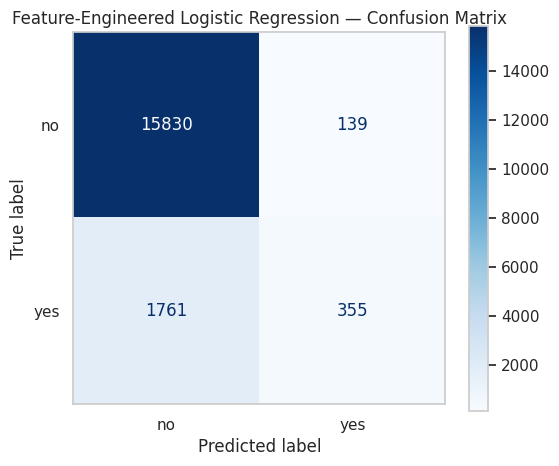

In [301]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_lr, fe_pred,
    display_labels=['no', 'yes'],
    cmap='Blues', values_format='d', ax=ax
)
ax.set_title('Feature-Engineered Logistic Regression — Confusion Matrix')
ax.grid(False)
plt.show()

The confusion matrix shows that the model correctly identifies 15,830 non-subscribers and 355 subscribers. It incorrectly classifies 139 non-subscribers as subscribers and misses 1,761 actual subscribers. Compared with the baseline model, the engineered model produces slightly more true positives and fewer false positives, indicating a modest improvement in identifying potential subscribers.



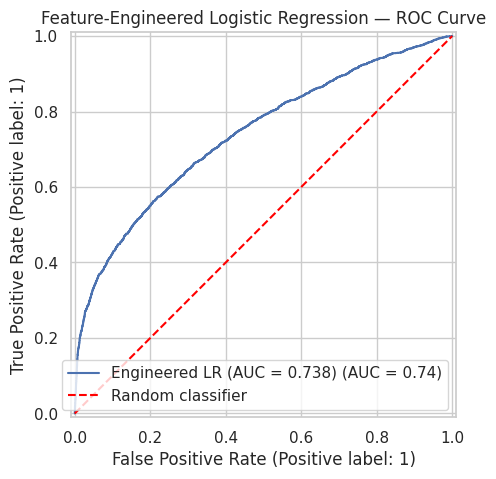

In [302]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(
    y_test_lr, fe_prob, ax=ax,
    name=f'Engineered LR (AUC = {fe_auc:.3f})'
)
ax.plot([0, 1], [0, 1], linestyle='--', color='red', label='Random classifier')
ax.set_title('Feature-Engineered Logistic Regression — ROC Curve')
ax.legend(loc='lower right')
plt.show()

After applying feature engineering, the Logistic Regression model achieves a ROC-AUC score of 0.738, compared with 0.734 for the baseline model. This represents a small improvement in the model's ability to distinguish between subscribers and non-subscribers.

The ROC curve remains above the diagonal line representing random classification, confirming that the model performs better than random guessing. However, the improvement in ROC-AUC is relatively small, and the model still fails to identify most actual subscribers.

Overall, feature engineering provides a slight improvement in predictive performance, but the results suggest that further parameter tuning may be necessary to improve the identification of subscribers.

### 5.2.1 Parameter Tuning

Feature engineering may not be enough on its own, so the next step tests different values of the regularization parameter `C` and whether to use `class_weight='balanced'`. Smaller `C` means stronger regularization. Balanced class weights place more emphasis on the minority `yes` class, which may improve its recall but can also increase false positives. A stratified 3-fold cross-validation search selects the settings with the highest mean ROC-AUC on the training data only. The held-out test set is used only for final evaluation.


In [303]:
# 3.2.3 Tune C and class_weight on the feature-engineered model
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

param_grid_lr = {
    'model__C': [0.01, 0.1, 1.0, 10.0],
    'model__class_weight': [None, 'balanced']
}
cv_lr = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

tuned_lr_search = GridSearchCV(
    estimator=engineered_lr,
    param_grid=param_grid_lr,
    scoring='roc_auc',
    cv=cv_lr,
    n_jobs=-1,
    refit=True
)
tuned_lr_search.fit(X_train_fe_lr, y_train_lr)
tuned_lr = tuned_lr_search.best_estimator_

tuned_pred = tuned_lr.predict(X_test_fe_lr)
tuned_prob = tuned_lr.predict_proba(X_test_fe_lr)[:, 1]
tuned_auc = roc_auc_score(y_test_lr, tuned_prob)

print('BEST PARAMETERS:', tuned_lr_search.best_params_)
print(f'Best mean CV ROC-AUC: {tuned_lr_search.best_score_:.4f}')
print('TUNED FEATURE-ENGINEERED LOGISTIC REGRESSION')
print(f'Accuracy: {accuracy_score(y_test_lr, tuned_pred):.4f}')
print(f'ROC-AUC:  {tuned_auc:.4f}')
print(classification_report(y_test_lr, tuned_pred, target_names=['no', 'yes'], zero_division=0))



BEST PARAMETERS: {'model__C': 0.1, 'model__class_weight': 'balanced'}
Best mean CV ROC-AUC: 0.7220
TUNED FEATURE-ENGINEERED LOGISTIC REGRESSION
Accuracy: 0.7270
ROC-AUC:  0.7379
              precision    recall  f1-score   support

          no       0.93      0.74      0.83     15969
         yes       0.24      0.60      0.34      2116

    accuracy                           0.73     18085
   macro avg       0.59      0.67      0.58     18085
weighted avg       0.85      0.73      0.77     18085



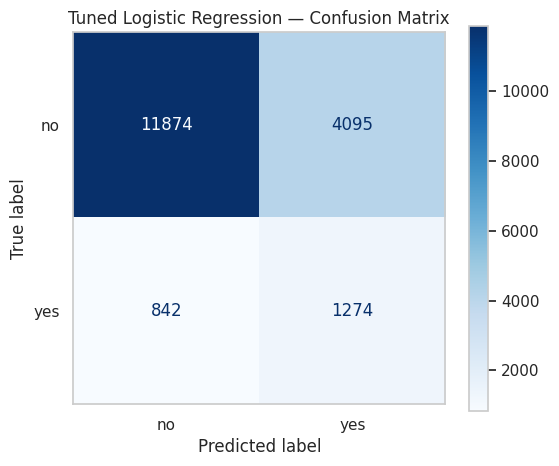

In [304]:

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_lr, tuned_pred, display_labels=['no', 'yes'],
    cmap='Blues', values_format='d', ax=ax
)
ax.set_title('Tuned Logistic Regression — Confusion Matrix')
ax.grid(False)
plt.show()

The tuned model correctly identifies 1,274 subscribers, compared with 355 in the feature-engineered model. It also reduces false negatives from 1,761 to 842, meaning that it identifies a much larger proportion of actual subscribers. However, this improvement comes at the cost of more false positives: 4,095 non-subscribers are incorrectly classified as subscribers, compared with 139 previously. The number of correctly identified non-subscribers also decreases from 15,830 to 11,874.

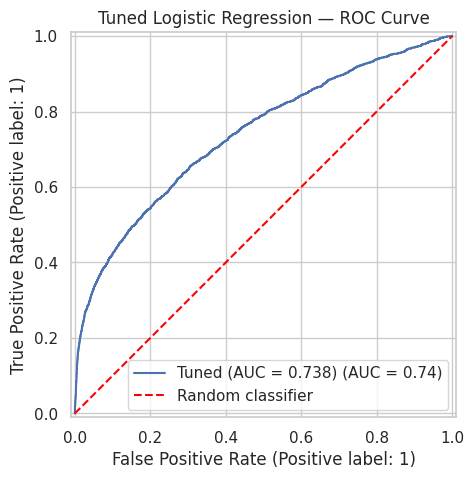

In [305]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(
    y_test_lr, tuned_prob, ax=ax, name=f'Tuned (AUC = {tuned_auc:.3f})'
)
ax.plot([0, 1], [0, 1], linestyle='--', color='red', label='Random classifier')
ax.set_title('Tuned Logistic Regression — ROC Curve')
ax.legend(loc='lower right')
plt.show()

After parameter tuning, the Logistic Regression model achieves a ROC-AUC score of 0.738, which is the same as the feature-engineered model when rounded to three decimal places. However, the confusion matrix shows a substantial change in classification performance.

The ROC curve remains above the diagonal, indicating that the model distinguishes between the two classes better than random guessing. Although the ROC-AUC remains approximately 0.738, parameter tuning has changed the model's classification behaviour, making it more sensitive to potential subscribers.

Overall, the tuned model is better at identifying subscribers but generates more false positives. The preferred model therefore depends on the objective: if identifying as many potential subscribers as possible is the priority, the tuned model may be more suitable. If minimizing false positives is more important, the baseline or feature-engineered model may be preferable.

### 5.2.3 Comparison and Interpretation

The table compares all three models on the same held-out test observations. Precision, recall, and F1-score refer to the positive `yes` class. ROC-AUC evaluates ranking across thresholds, while the confusion matrices use the default prediction threshold of 0.5. Interpret the results together: a change in accuracy alone is not sufficient evidence of improvement, especially with an imbalanced target.

In [306]:
# 3.2.4 Compare baseline, feature engineering, and tuned model
from sklearn.metrics import precision_score, recall_score, f1_score

models_lr = [
    ('Baseline Logistic Regression', baseline_pred, baseline_auc),
    ('Feature-Engineered Logistic Regression', fe_pred, fe_auc),
    ('Tuned Feature-Engineered Logistic Regression', tuned_pred, tuned_auc)
]
comparison_lr = pd.DataFrame([
    {
        'Model': name,
        'Accuracy': accuracy_score(y_test_lr, pred),
        'Precision (yes)': precision_score(y_test_lr, pred, zero_division=0),
        'Recall (yes)': recall_score(y_test_lr, pred, zero_division=0),
        'F1-score (yes)': f1_score(y_test_lr, pred, zero_division=0),
        'ROC-AUC': auc_value
    }
    for name, pred, auc_value in models_lr
])
display(comparison_lr.round(4))

best_auc_model = comparison_lr.loc[comparison_lr['ROC-AUC'].idxmax(), 'Model']
best_recall_model = comparison_lr.loc[comparison_lr['Recall (yes)'].idxmax(), 'Model']
print(f"Highest test ROC-AUC: {best_auc_model}")
print(f"Highest recall for subscribers ('yes'): {best_recall_model}")


,Model,Accuracy,Precision (yes),Recall (yes),F1-score (yes),ROC-AUC
0,Baseline Logistic Regression,0.8941,0.7039,0.1640,0.2660,0.7336
1,Feature-Engineered Logistic Regression,0.8949,0.7186,0.1678,0.2720,0.7378
2,Tuned Feature-Engineered Logistic Regression,0.7270,0.2373,0.6021,0.3404,0.7379


Highest test ROC-AUC: Tuned Feature-Engineered Logistic Regression
Highest recall for subscribers ('yes'): Tuned Feature-Engineered Logistic Regression


## 5.3 XGBoost with feature engineering

To improve the ability of the classifier to predict the correct class for each new client, several strategies are implemented and tested in order to discuss the results obtained and the variation between the baseline XGBoost and configured XGBoost.

The strategies adopted are the following ones:
- Feature engineering
- Undersampling 'no' class
- Oversampling 'yes' class

In this attempt to improve the classifier, a k fold validation set and Hyperparameter configuration is employed.

Specifically, cross-validation with 5 folds and n_estimators increased and scale pos weight to handle class imbalance.


In [307]:
from sklearn.model_selection import StratifiedKFold, train_test_split
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc, RocCurveDisplay
import matplotlib.pyplot as plt


X_fe = X.copy()

columns_to_drop_fe = ['contact', 'day_of_week', 'month', 'duration']
X_fe = X_fe.drop(columns=columns_to_drop_fe, errors='ignore')


X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe, y, test_size=0.40, random_state=42
)


le_fe = LabelEncoder()
y_train_encoded_fe = le_fe.fit_transform(y_train_fe.values.ravel())
y_test_encoded_fe = le_fe.transform(y_test_fe.values.ravel())


num_features_fe = ['age', 'balance', 'campaign', 'pdays', 'previous', 'previously_contacted']
cat_features_fe = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'poutcome', 'age_category']

preprocessor_fe = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features_fe),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features_fe)
    ])


X_train_processed_fe = preprocessor_fe.fit_transform(X_train_fe)
X_test_processed_fe = preprocessor_fe.transform(X_test_fe)


In [308]:

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = []

print("Starting Cross-Validation (5 fold)...\n")

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train_processed_fe, y_train_encoded_fe)):
    X_tr, y_tr = X_train_processed_fe[train_idx], y_train_encoded_fe[train_idx]
    X_va, y_va = X_train_processed_fe[val_idx], y_train_encoded_fe[val_idx]


    model_cv = xgb.XGBClassifier(
        max_depth=8,
        learning_rate=0.3,
        n_estimators=300,
        objective='binary:logistic',
        random_state=42,
        early_stopping_rounds=15
    )

    model_cv.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        verbose=False
    )

    preds_val = model_cv.predict(X_va)
    acc = accuracy_score(y_va, preds_val)
    cv_scores.append(acc)
    print(f"Fold {fold + 1} - Accuracy on Validation Set: {acc:.4f}")

print(f"\nAverage accuracy in Cross-Validation: {np.mean(cv_scores):.4f} +/- {np.std(cv_scores):.4f}")

Starting Cross-Validation (5 fold)...

Fold 1 - Accuracy on Validation Set: 0.8916
Fold 2 - Accuracy on Validation Set: 0.8874
Fold 3 - Accuracy on Validation Set: 0.8909
Fold 4 - Accuracy on Validation Set: 0.8935
Fold 5 - Accuracy on Validation Set: 0.8920

Average accuracy in Cross-Validation: 0.8911 +/- 0.0020


It is applied a cross validation with 5 folds and the accuracy on the validation set is on average 0.89.

In [309]:

X_train_fit, X_val_fit, y_train_fit, y_val_fit = train_test_split(
    X_train_processed_fe, y_train_encoded_fe, test_size=0.20, random_state=42
)


# Calculate class imbalance
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive


bst_fe = xgb.XGBClassifier(
    max_depth=8,
    learning_rate=0.3,
    n_estimators=300,
    objective='binary:logistic',
    random_state=42,
    scale_pos_weight=scale_pos_weight,
    early_stopping_rounds=15
)

bst_fe.fit(
    X_train_fit,
    y_train_fit,
    eval_set=[(X_val_fit, y_val_fit)],
    verbose=False
)


preds_fe = bst_fe.predict(X_test_processed_fe)
y_probs_fe = bst_fe.predict_proba(X_test_processed_fe)[:, 1]


print(f"Accuracy on Test Set (New model): {accuracy_score(y_test_encoded_fe, preds_fe):.4f}\n")
print(classification_report(y_test_encoded_fe, preds_fe, target_names=['no', 'yes']))

Accuracy on Test Set (New model): 0.8284

              precision    recall  f1-score   support

          no       0.91      0.89      0.90     15984
         yes       0.30      0.36      0.33      2101

    accuracy                           0.83     18085
   macro avg       0.61      0.62      0.61     18085
weighted avg       0.84      0.83      0.83     18085



The classification report shows an accuracy on Test set of 0.83 slightly lower than the classifier we used as baseline.

The precision and recall values are also slightly different showing an increase of the recall for the class yes 0.18 -> 0.36 meaning that the model increase its ability to identify from all the clients that have suscribed to a term deposit, the 36% of them. On the other hand, the precision dropped significantly from 0.57 -> 0.30 meaning that of the samples predicted as 'yes', just the 30% have subscribed to a term deposit.

Analyzing the 'no' class, the recall dropped significantly from 0.98 -> 0.89 meaning the from all the clients that haven't subscribed to a term deposit, the model correctly identified 89% but the precision increased of 1 point from 90 -> 91, meaning the from all the samples predicted as 'no', 91% were correctly identified as clients that haven't subscribed to a term deposit.

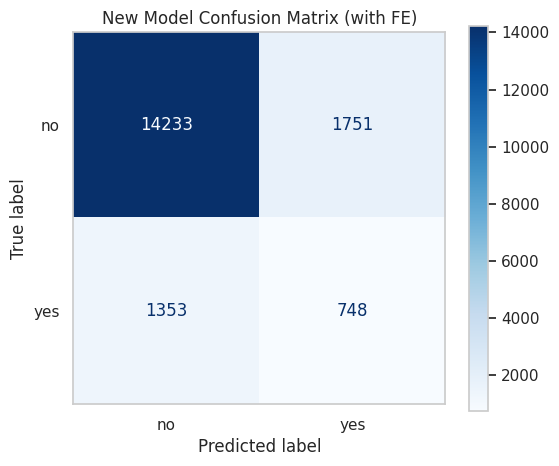

In [310]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_fe = confusion_matrix(y_test_encoded_fe, preds_fe)
fig, ax1 = plt.subplots(figsize=(6, 5))
disp_cm_fe = ConfusionMatrixDisplay(confusion_matrix=cm_fe, display_labels=['no', 'yes'])
disp_cm_fe.plot(ax=ax1, cmap='Blues', values_format='d')
ax1.set_title('New Model Confusion Matrix (with FE)')
ax1.grid(False)
plt.show()

The confusion matrix shows starting from the top left, that the classifier predicted correctly 14233 (-1464 with respect to the baseline model) 'no' class, and 748 (+373 with respect to the baseline model) 'yes' class.

The classifier predicted wrongly as false negative 1353 (- 373 with respect to the baseline model) and 1751 false positive (+1464 with respect to the baseline model).

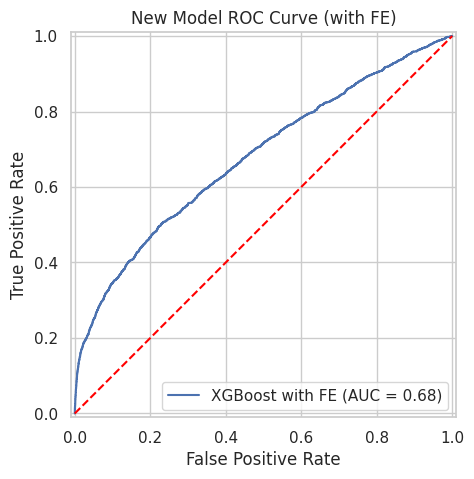

In [311]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, RocCurveDisplay

fpr_fe, tpr_fe, _ = roc_curve(y_test_encoded_fe, y_probs_fe)
roc_auc_fe = auc(fpr_fe, tpr_fe)

fig, ax2 = plt.subplots(figsize=(6, 5))
disp_roc_fe = RocCurveDisplay(fpr=fpr_fe, tpr=tpr_fe, roc_auc=roc_auc_fe, estimator_name='XGBoost with FE')
disp_roc_fe.plot(ax=ax2)
ax2.plot([0, 1], [0, 1], color='red', linestyle='--')
ax2.set_title('New Model ROC Curve (with FE)')
plt.show()

The ROC curve shows the classifier at different thresholds decreased its ability to distinguish between the two classes since the curve is closer to the red diagonal line than the baseline model. The AUC also decreased (from 0.72 -> 0.68)

### 5.3.1 Solving Imbalancing: Undersampling 'no' class




In this section, to improve the ability of the classifier to discriminate between the two classes that are influenced from the imbalancing problem of the dataset, undersampling the 'no' class is employed.

In [312]:
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc, RocCurveDisplay
import matplotlib.pyplot as plt

idx_no = np.where(y_train_encoded_fe == 0)[0]
idx_yes = np.where(y_train_encoded_fe == 1)[0]

num_no = len(idx_no)
num_yes = len(idx_yes)
print(f"Class imbalance: Class 'no' (0): {num_no}, Class 'yes' (1): {num_yes}")


np.random.seed(42)
idx_no_undersampled = np.random.choice(idx_no, size=num_yes, replace=False)


idx_balanced = np.concatenate([idx_no_undersampled, idx_yes])
np.random.shuffle(idx_balanced)


X_train_balanced = X_train_processed_fe[idx_balanced]
y_train_balanced = y_train_encoded_fe[idx_balanced]

print(f"Undersampling - Class 'no' (0): {len(idx_no_undersampled)}, Class 'yes' (1): {num_yes}\n")


bst_balanced = xgb.XGBClassifier(
    max_depth=5,
    learning_rate=0.5,
    n_estimators=300,
    objective='binary:logistic',
    random_state=42
)

bst_balanced.fit(X_train_balanced, y_train_balanced)


preds_balanced = bst_balanced.predict(X_test_processed_fe)
y_probs_balanced = bst_balanced.predict_proba(X_test_processed_fe)[:, 1]


print(f"Accuracy on Test Set (Balanced model): {accuracy_score(y_test_encoded_fe, preds_balanced):.4f}\n")
print(classification_report(y_test_encoded_fe, preds_balanced, target_names=['no', 'yes']))

Class imbalance: Class 'no' (0): 23938, Class 'yes' (1): 3188
Undersampling - Class 'no' (0): 3188, Class 'yes' (1): 3188

Accuracy on Test Set (Balanced model): 0.6531

              precision    recall  f1-score   support

          no       0.93      0.66      0.77     15984
         yes       0.19      0.63      0.30      2101

    accuracy                           0.65     18085
   macro avg       0.56      0.64      0.53     18085
weighted avg       0.84      0.65      0.71     18085



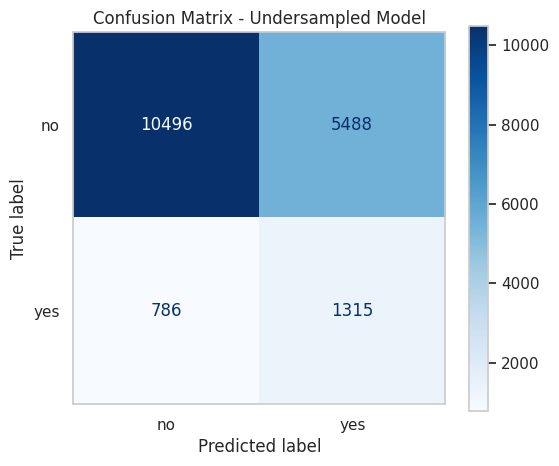

In [313]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_bal = confusion_matrix(y_test_encoded_fe, preds_balanced)
fig, ax1 = plt.subplots(figsize=(6, 5))
disp_cm_bal = ConfusionMatrixDisplay(confusion_matrix=cm_bal, display_labels=['no', 'yes'])
disp_cm_bal.plot(ax=ax1, cmap='Blues', values_format='d')
ax1.set_title('Confusion Matrix - Undersampled Model')
ax1.grid(False)
plt.show()


By undersampling the majority class (`no` changed from 23,938 to 3,188 samples), we balanced the dataset during training. This choice drastically altered the model's prediction dynamics:
The overall accuracy dropped significantly from 89% down to **65.31%**. Since the test set remains highly imbalanced, predicting more aggressively towards the minority class inevitably reduces the overall fraction of correct predictions.

Analyzing the class 'yes', Recall surged from 18% in the baseline model up to **63.0%**. The model now successfully flags nearly two-thirds of the customers who will actually subscribe, which is a major operational benefit.

About the precision, to capture those subscribers, the model is much less conservative. Out of all clients predicted to subscribe, only **19.0%** eventually do. This translates to a high number of false alarms (5,488 non-subscribers incorrectly targeted).
Analyzing the class 'no', with a Recall of 0.66, the model correctly isolates only **66.0%** of the true non-subscribers, compared to 98% in the baseline.
The Precision is 93.0% meaning that if the model predicts a customer will not subscribe, we can be highly confident (**93.0%**) in that prediction.

**Business Trade-off**: This configuration is highly aggressive. While it successfully intercepts most of the potential interest (63.0% recall), it generates 5,488 wasted calls. It is suitable only if the operational cost of making an extra call is extremely low.

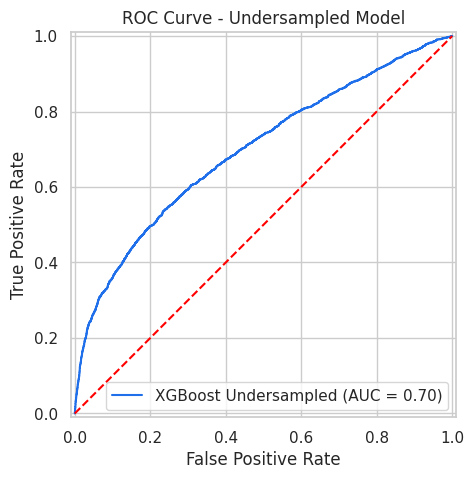

In [314]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, RocCurveDisplay


fpr_bal, tpr_bal, _ = roc_curve(y_test_encoded_fe, y_probs_balanced)
roc_auc_bal = auc(fpr_bal, tpr_bal)

fig, ax2 = plt.subplots(figsize=(6, 5))
disp_roc_bal = RocCurveDisplay(fpr=fpr_bal, tpr=tpr_bal, roc_auc=roc_auc_bal, estimator_name='XGBoost Undersampled')
disp_roc_bal.plot(ax=ax2, color='#1f6feb')
ax2.plot([0, 1], [0, 1], color='red', linestyle='--')
ax2.set_title('ROC Curve - Undersampled Model')
plt.show()

**AUC is 0.70**. In simple terms, if we randomly select one customer who subscribed and one who did not, there is a **70% chance** the model will assign a higher probability of subscription to the actual subscriber.
While 0.70 represents a moderate and useful predictive power, it is slightly lower than our baseline models. This confirms that balancing the classes helps us target the correct people more aggressively (higher recall), but makes the overall probability rankings slightly less precise across the entire dataset.

### 5.3.2 Solving Imbalancing: Oversampling 'yes' class


In [315]:
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc, RocCurveDisplay
import matplotlib.pyplot as plt


idx_no = np.where(y_train_encoded_fe == 0)[0]
idx_yes = np.where(y_train_encoded_fe == 1)[0]

num_no = len(idx_no)
num_yes = len(idx_yes)
print(f"Class Imbalance - Class 'no' (0): {num_no}, Class 'yes' (1): {num_yes}")

np.random.seed(42)
idx_yes_oversampled = np.random.choice(idx_yes, size=num_no, replace=True)

idx_balanced_over = np.concatenate([idx_no, idx_yes_oversampled])
np.random.shuffle(idx_balanced_over)

X_train_oversampled = X_train_processed_fe[idx_balanced_over]
y_train_oversampled = y_train_encoded_fe[idx_balanced_over]

print(f"Oversampling - Class 'no' (0): {num_no}, Class 'yes' (1): {len(idx_yes_oversampled)}\n")

bst_oversampled = xgb.XGBClassifier(
    max_depth=5,
    learning_rate=0.3,
    n_estimators=150,
    objective='binary:logistic',
    random_state=42
)

bst_oversampled.fit(X_train_oversampled, y_train_oversampled)

preds_oversampled = bst_oversampled.predict(X_test_processed_fe)
y_probs_oversampled = bst_oversampled.predict_proba(X_test_processed_fe)[:, 1]

print(f"Accuracy sul Test Set (Oversampled model): {accuracy_score(y_test_encoded_fe, preds_oversampled):.4f}\n")
print(classification_report(y_test_encoded_fe, preds_oversampled, target_names=['no', 'yes']))

Class Imbalance - Class 'no' (0): 23938, Class 'yes' (1): 3188
Oversampling - Class 'no' (0): 23938, Class 'yes' (1): 23938

Accuracy sul Test Set (Oversampled model): 0.7863

              precision    recall  f1-score   support

          no       0.93      0.82      0.87     15984
         yes       0.27      0.50      0.35      2101

    accuracy                           0.79     18085
   macro avg       0.60      0.66      0.61     18085
weighted avg       0.85      0.79      0.81     18085



When we used oversampling to balance the dataset, the XGBoost model achieved a 78.63% overall accuracy and a ROC-AUC of 0.71.

Looking closely at the positive class (the customers who actually subscribed):

Recall was 50.20%: The model successfully caught about half of the actual subscribers (1,054 out of 2,101).
Precision was 27.00%: Since the model targeted potential subscribers more aggressively, only about 1 in 4 recommended calls actually led to a subscription.
F1-Score was 35.00%: This was actually the highest balanced score achieved among our different XGBoost configurations.

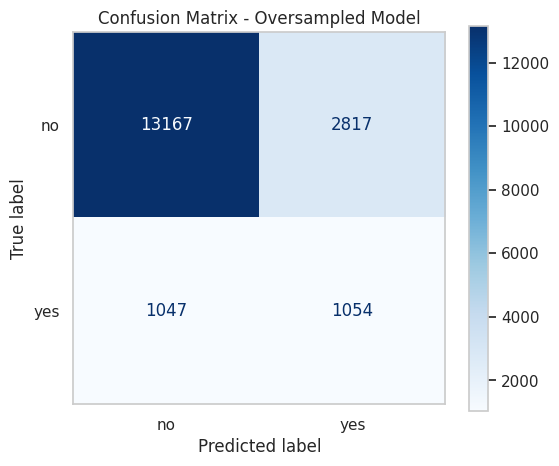

In [316]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


cm_bal = confusion_matrix(y_test_encoded_fe, preds_oversampled)
fig, ax1 = plt.subplots(figsize=(6, 5))
disp_cm_bal = ConfusionMatrixDisplay(confusion_matrix=cm_bal, display_labels=['no', 'yes'])
disp_cm_bal.plot(ax=ax1, cmap='Blues', values_format='d')
ax1.set_title('Confusion Matrix - Oversampled Model')
ax1.grid(False)
plt.show()

The matrix breaks down what happened to the **18,085 customers in our test set**:
**True "No" (13,167)**: These are the uninterested customers that the model correctly identified. The model is highly reliable here.
**True "Yes" (1,054)**: These are the customers who actually subscribed, and whom the model successfully identified (representing **50.2% of the total 2,101 actual subscribers**).
False Positives (2,817)**: These are uninterested customers whom the model predicted would subscribe. In a real marketing campaign, these represent wasted phone calls.
False Negatives (1,047)**: These are customers who would have subscribed, but the model missed them and predicted they would not.

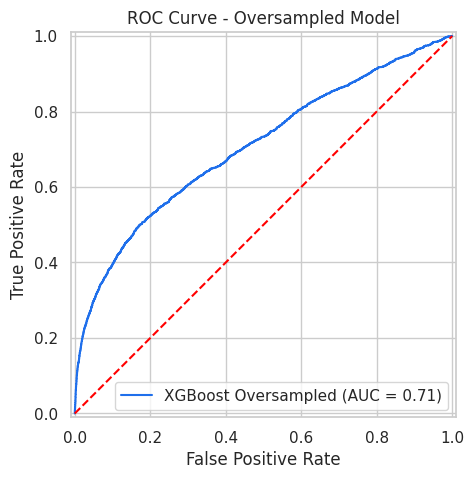

In [317]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, RocCurveDisplay


fpr_bal, tpr_bal, _ = roc_curve(y_test_encoded_fe, y_probs_oversampled)
roc_auc_bal = auc(fpr_bal, tpr_bal)

fig, ax2 = plt.subplots(figsize=(6, 5))
disp_roc_bal = RocCurveDisplay(fpr=fpr_bal, tpr=tpr_bal, roc_auc=roc_auc_bal, estimator_name='XGBoost Oversampled')
disp_roc_bal.plot(ax=ax2, color='#1f6feb')
ax2.plot([0, 1], [0, 1], color='red', linestyle='--')
ax2.set_title('ROC Curve - Oversampled Model')
plt.show()

Compared to the Undersampling approach (which generated 5,488 false alarms), the Oversampled model **cuts wasted calls nearly in half** (dropping to 2,817). However, the trade-off is that it identifies fewer actual subscribers (1,054 instead of 1,315).

The **AUC of 0.71** (71%) means that if we randomly pick one subscriber and one non-subscriber from our dataset, the model will correctly rank the actual subscriber higher in our contact list **71% of the time**.

This demonstrates moderate and useful predictive power (substantially better than random guessing at 50%), though it shows that oversampling provides a similar level of overall class discrimination to undersampling (0.70).

## 5.4 Random Forest Classification improvements
To improve the Random Forest model, we tested different classification thresholds: 0.1, 0.3, 0.5, 0.7 and 0.9.

As expected, lower threshold values lead to lower precision but higher recall. In this case, the model identifies more potential subscribers, reducing false negatives (missing customers who may actually subscribe), but also increasing false positives.

On the other hand, higher thresholds increase precision but reduce recall. This means that the model makes fewer false alarms, but it may fail to identify some customers who would be interested in subscribing.

Maybe the best tradeoff is around 0.3 or 0.5, since it's better doing more calls even if most of them don't acquire new customer. Moreover in this range the F1-score has the highest value.

In [318]:
y_test_binary = y_test.astype(int)

# Thresholds to compare
thresholds = [0.1, 0.3, 0.5, 0.7, 0.9]

results = {}

for threshold in thresholds:

    # Predictions created with the current threshold
    y_pred_threshold = (y_prob_rf >= threshold).astype(int)

    # Save the metrics
    results[f"Threshold {threshold:.2f}"] = {
        "Precision": precision_score(
            y_test_binary, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test_binary, y_pred_threshold, zero_division=0
        ),
        "F1-score": f1_score(
            y_test_binary, y_pred_threshold, zero_division=0
        )
    }

# Metrics on rows, thresholds on columns
threshold_summary = pd.DataFrame(results).round(3)

display(threshold_summary)

,Threshold 0.10,Threshold 0.30,Threshold 0.50,Threshold 0.70,Threshold 0.90
Precision,0.264,0.414,0.532,0.651,0.825
Recall,0.983,0.900,0.717,0.367,0.069
F1-score,0.417,0.567,0.611,0.470,0.128


# 6 Interpret the Result

##6.1 Interpret Logistic Regression Classification results

The Logistic Regression models demonstrate different trade-offs between correctly identifying subscribers and avoiding false positive predictions. The baseline model achieves an accuracy of 89.41% and a ROC-AUC of 0.7336. However, its recall for subscribers is only 16%, meaning that it identifies a relatively small proportion of customers who actually subscribe to a term deposit.

| Logistic Regression Strategy | Accuracy | Precision (yes) | Recall (yes) | F1-Score (yes) | ROC-AUC |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Baseline Model** | 89.41% | 70.39% | 16.40% | 26.60% | 0.73 |
| **Feature Engineered (FE)** | 89.49% | 71.86% | 16.78% | 27.20% | 0.74 |
| **Tuned FE (Balanced Weight)** | 72.70% | 23.73% | 60.21% | 34.04% | 0.74 |

---


After feature engineering, the ROC-AUC increases slightly to 0.738. The model also identifies 355 subscribers, compared with 347 in the baseline model, while reducing false positives from 146 to 139. This indicates a modest improvement in classification performance, although the overall change is limited.

Following parameter tuning, the model identifies 1,274 subscribers and reduces false negatives from 1,761 to 842. However, false positives increase substantially to 4,095, meaning that many non-subscribers are incorrectly classified as potential subscribers. Despite this change, the ROC-AUC remains approximately 0.738, suggesting that the model's overall ability to distinguish between the two classes has not materially improved.

Overall, the results highlight the importance of evaluating classification models using multiple metrics rather than accuracy alone. The baseline and feature-engineered models are more conservative in predicting subscriptions, whereas the tuned model prioritizes identifying more actual subscribers at the cost of increased false positives. The most appropriate model depends on the business objective: identifying as many potential subscribers as possible or minimizing incorrect positive predictions.

##6.2 Interpret XGBoost Classification results


To address class imbalance and optimize our predictive targeting, we evaluated four distinct XGBoost configurations. Below is a structured summary of their performance metrics on the test dataset:

| XGBoost Strategy | Accuracy | Precision (yes) | Recall (yes) | F1-Score (yes) | ROC-AUC |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Baseline Model** | 88.87% | 57.12% | 17.85% | 27.14% | 0.72 |
| **Feature Engineered (FE)** | 82.84% | 30.00% | 35.60% | 33.00% | 0.68 |
| **Undersampling 'no'** | 65.31% | 19.00% | 63.00% | 30.00% | 0.70 |
| **Oversampling 'yes'** | 78.63% | 27.00% | 50.20% | 35.00% | 0.71 |

---



The XGBoost models demonstrate different trade-offs between correctly identifying subscribers and avoiding false positive predictions. The baseline model achieves a high overall accuracy of 88.87% and solid precision of 57.12%. However, due to severe class-imbalance bias, its recall for subscribers is only 17.85%, meaning that it fails to identify over 82% of actual subscribing customers, which severely limits its utility for an active marketing acquisition campaign.

After applying feature engineering and adjusting class weights dynamically, the model's sensitivity increases, doubling the recall to 35.60% compared to the baseline. However, this expansion of the target pool comes at the cost of precision, which drops to 30.00%, meaning that approximately seven out of ten recommended calls are still false alarms.

To further tackle the imbalancing issue, the undersampling strategy aggressively balances the training dataset, resulting in the highest overall recall of 63.00%. While this approach successfully sweeps the market to capture almost two-thirds of all potential subscribers, it suffers from a low precision of 19.00% and generates 5,488 false alarms. Consequently, this highly aggressive strategy is operationally viable only if the cost of placing additional phone calls is negligible.

In contrast, the oversampling strategy represents the most balanced operational compromise, achieving the highest positive class F1-score of 35.00% alongside a stable ROC-AUC of 0.71. It successfully intercepts 50.20% of actual subscribers while keeping false alarms restricted to 2,817. Compared to the undersampling approach, oversampling cuts wasted calls nearly in half while still capturing a substantial portion of the target market, making it a highly robust and reliable choice for optimizing campaign resources.

## 6.3 Interpret Random Forest Classification results

The Random Forest results show a clear trade-off between precision and recall at different classification thresholds.

| Random Forest Strategy | Accuracy | Precision (yes) | Recall (yes) | F1-Score (yes) | ROC-AUC |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **RF Threshold 0.1** | 68.02% | 26.44% | 98.33% | 41.67% | 0.93 |
| **RF Threshold 0.3** | 84.06% | 41.44% | 89.96% | 56.74% | 0.93 |
| **RF Threshold 0.5** | 89.39% | 53.23% | 71.68% | 61.10% | 0.93 |
| **RF Threshold 0.7** | 90.36% | 65.09% | 36.74% | 46.97% | 0.93 |
| **RF Threshold 0.9** | 89.02% | 82.49% | 6.95% | 12.82% | 0.93 |

At a low threshold of 0.10, the model identifies almost all potential subscribers (since the recall is 0.983), but precision is low (0.264), meaning that many contacted customers are unlikely to subscribe. Increasing the threshold improves precision, reaching 0.825 at 0.90, but recall drops substantially to 0.069.

The best balance is obtained at the standard threshold of 0.50, which achieves the highest F1-score (0.611), with precision equal to 0.532 and recall equal to 0.717.

From a business perspective, a lower threshold may be preferable when the cost of contacting customers is low and the goal is to reach as many potential subscribers as possible; a higher threshold is more suitable when the bank wants to limit unnecessary calls.

Regarding computational resources, if less processing power is available, the model can be simplified by reducing the number of trees (n_estimators), limiting the maximum depth of each tree (max_depth), or increasing the minimum number of samples required in a leaf (min_samples_leaf). These choices reduce training time and memory usage, although they may slightly decrease predictive performance. On the other hand, with more computational power, it would be possible to train a larger forest with more trees, test a wider range of hyperparameters through cross-validation, and use techniques such as RandomizedSearchCV or GridSearchCV to identify a more effective configuration. This could improve the robustness of the model, but it would require longer training times.


# Conclusion

Based on the analysis of the dataset and the application of algorithms Logistic Regression, XGBoost and Random Forest, it is possible to recommend to the bank a possible strategy to achieve the goal of predicting clients subscribing to a term deposit or not.

The **Random Forest Classifier** achieved the highest overall discriminative power with an **ROC-AUC of 0.93**, vastly outperforming Logistic Regression (0.74) and XGBoost (0.71-0.72).

With a default threshold of 0.50 and balanced class weights, Random Forest correctly captures **71.68%** of actual subscribers (Recall) while maintaining a respectable precision of **53.23%**.

The bank should dynamically adjust the Random Forest decision threshold based on budget and campaign priorities:
**Aggressive Acquisition (Low Cost per Call)**: Deploy with a **0.30 threshold** to capture **89.96%** of potential subscribers. This maximizes revenue but increases total calls.

**High Efficiency (High Cost per Call)**: Deploy with a **0.70 threshold** to increase precision to **65.09%**, minimizing wasted resources on uninterested customers.

WIth regard to data optimization strategies, it is important to evaluate features importance: **Feature Exclusion (Prevent Data Leakage)**: Never deploy the model with `duration` included, as call duration is unknown prior to dialing and prioritize customers with previous successful campaigns (`poutcome`), student/retired demographics (`job`), and target outreach during historically high-conversion months like March, September, October, and December.
```